# KO5 — AlphaMissense Threshold Classifier

## Overview

This notebook implements **Key Objective 5**: classifying PDAC patients versus healthy individuals using a single feature — the maximum AlphaMissense (AM) pathogenicity score across all genes per patient.

An F₁-optimal threshold is found on the training fold in each cross-validation split to separate somatic (PDAC) from germline (healthy) samples. Performance is evaluated with **5-fold stratified cross-validation repeated across 100 bootstrap resamples** of the healthy cohort (100 × 5 = 500 per-fold results); all reported metrics are cross-validated medians. Bootstrap iteration 15 — the resample closest to the subagging median on F1, precision, and recall — is used for illustrative figures. One patient (TCGA-IB-7651) is a hypermutator and is excluded from all classifier metrics.

The notebook produces: a three-panel performance figure (PR curve, confusion matrix, AM score strip plot); key ML metrics and a classification breakdown table; a table of highly pathogenic mutations above the threshold; a per-patient mutation landscape figure; and AM score distribution plots for 23 genes of interest.

## Data

**Input**
- `../3_Data/merged_tcga_1000G.parquet` — merged somatic (TCGA-PAAD, `source == 'TCGA'`, 168 patients) and germline (1000 Genomes, `source == '1000G'`, 3,202 individuals) mutations. Columns used: `source`, `gene_name`, `sample_id`, `am_pathogenicity`, `protein_variant`.
- `../3_Data/healthy_downsampled_bootstrap.parquet` — 100 balanced bootstrap resamples (bootstrap_id 0–99; generated by `1_Pipeline/4_Healthy_Bootstrap.ipynb`) of the healthy cohort (3,202 individuals each), used for subagging.
- `../Data/driver_like_genes.parquet` — driver-like gene ranking with CLES lower-bound values.

**Cached computation** (loaded if present; computed and saved on first run)
- `../Data/M1_C3_subagging_cache.json` — 100 subagging iterations: per-iteration threshold, TP / FN / FP / TN counts.
- `../Data/M1_G_subagging_cache.json` — 100 × 5-fold cross-validation results (F1, precision, recall, specificity, AUPRC, AUROC per fold).
- `../Data/M1_boot_cache_c.json` — 100 apparent-performance iterations (training-set estimates, no cross-validation).
- `../Data/M1_H_bootstrap_cache.json` — 100-iteration bootstrap of fold-level AUROC, used in the cross-method comparison.

**Output**
- `../Figures/KO5_*.{pdf,png,svg}` — all figures produced by this notebook.

## Method

- **Feature**: maximum AlphaMissense pathogenicity score per patient across all genes — a single continuous value per sample.
- **Threshold**: F₁-optimal threshold derived on the training fold of each CV split; never fitted to the test fold (no leakage).
- **Subagging**: 100 bootstrap resamples of the healthy cohort; the PDAC cohort is fixed across all resamples.
- **Cross-validation**: 5-fold stratified CV per bootstrap resample → 500 per-fold results in total.
- **Reported values**: cross-validated medians; 95% CIs from the 2.5th–97.5th percentiles of the 500-fold distribution.
- **Representative iteration**: bootstrap_id = 15, the resample closest to the subagging median on F1, precision, and recall; used for the illustrative confusion matrix and strip plot.
- **Pathogenicity categories** (AlphaMissense thresholds): benign < 0.34 ≤ uncertain < 0.564 ≤ pathogenic.

## Content

| # | Section | Description |
|---|---------|-------------|
| 1 | Setup & Computation | Imports, data loading, helper functions, and subagging / cross-validation with cache |
| 2 | Performance Figure | Three-panel figure: PR curve (AUPRC), confusion matrix, and AM score strip plot |
| 3 | Key ML Metrics Table | AUPRC, AUROC, F1, Precision, Recall, Specificity — 500-fold CV medians and 95% CIs |
| 4 | Classification Breakdown Table | TP / FN / FP / TN counts with FN sub-groups (with vs without pathogenic mutations) |
| 5 | Highly Pathogenic Mutations Table | Hotspot residues and genes with AM above the F₁-optimal threshold |
| 6 | Mutation Landscape Figure | Per-patient mutation map: 9 hotspot rows + 21 gene rows, cascade-ordered by mutation priority |
| 7 | Score Distributions & Effect Size | AM score distributions (PDAC vs Healthy) and CLES lower bound for 4 canonical drivers + GNAS + 19 driver-like genes |
| 8 | Cross-Method Comparison | Apparent vs cross-validated performance table and metric box plots over 500 folds |

## 1. Setup & Computation

In [4]:
import re
import numpy as np
import polars as pl
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu
from sklearn.metrics import (
    f1_score, fbeta_score, confusion_matrix,
    precision_recall_curve, auc,
    precision_score, recall_score,
    matthews_corrcoef, roc_auc_score,
)
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

pl.Config.set_tbl_rows(-1)

polars.config.Config

In [ ]:
sns.set_theme(style='whitegrid', context='paper', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 130})

COLOR_PDAC    = '#E69F00'
COLOR_HEALTHY = '#56B4E9'
DRIVER_GENES  = ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']
AM_PATH_MIN   = 0.564
AM_BENIGN_MAX = 0.34   # upper limit benign zone (same as 03_validation_RQ12)
CLES_LB_MIN   = 0.70
RANDOM_SEED   = 42
NOTEBOOK_PREFIX = 'KO5'

out_dir = Path('../Figures')
out_dir.mkdir(exist_ok=True)

WONG = {
    'orange':    '#E69F00', 'sky_blue': '#56B4E9', 'green':    '#009E73',
    'blue':      '#0072B2', 'vermilion':'#D55E00', 'pink':     '#CC79A7',
}

NETWORK_DATA = Path('/zfsdata/BRP_DF/data')
# LOCAL_DATA   = Path(r'C:/Users/daane/Desktop/DATA')
LOCAL_DATA   = Path(r'C:/2604_BRP/Data')
DATA_DIR     = NETWORK_DATA if NETWORK_DATA.exists() else LOCAL_DATA
REPO_DATA    = Path('../3_Data')   # merged + healthy bootstrap parquets shipped with the repo

print(f'Data dir    : {DATA_DIR}')
print(f'AM_PATH_MIN : {AM_PATH_MIN}')
print(f'CLES_LB_MIN : {CLES_LB_MIN}')

Data dir    : ..\3_Data\merged_tcga_1000G.parquet
AM_PATH_MIN : 0.564
CLES_LB_MIN : 0.7


In [6]:
tcga = (
    pl.read_parquet(REPO_DATA / 'merged_tcga_1000G.parquet')
    .filter(pl.col('source') == 'TCGA')
    .select(['sample_id', 'gene_name', 'protein_variant', 'am_pathogenicity'])
)
HEALTHY_BOOT_PATH = REPO_DATA / 'healthy_downsampled_bootstrap.parquet'
# bootstrap_id=0 is the primary sample (first of 100, seed 42)
g1000_ds = (
    pl.read_parquet(HEALTHY_BOOT_PATH)
    .filter(pl.col('bootstrap_id') == 0)
    .select(['sample_id', 'gene_name', 'protein_variant', 'am_pathogenicity'])
)
df_m1    = pl.concat([tcga, g1000_ds])

print(f'TCGA rows       : {len(tcga):,}   ({tcga["sample_id"].n_unique()} patients)')
print(f'Healthy ds rows : {len(g1000_ds):,}  ({g1000_ds["sample_id"].n_unique()} individuals)')
print(f'df_m1 rows      : {len(df_m1):,}')
print(f'df_m1 schema    : {df_m1.schema}')

FileNotFoundError: The system cannot find the path specified. (os error 3): ../3_Data/merged_tcga_1000G.parquet/merged_tcga_1000G.parquet

In [5]:
ranking_table     = pl.read_parquet(DATA_DIR / 'driver_like_genes.parquet')
selected_genes    = set(ranking_table['gene_name'].to_list())
gene_list_ordered = ranking_table['gene_name'].to_list()
driver_genes      = ranking_table.filter(pl.col('is_driver'))['gene_name'].to_list()
assert set(driver_genes) == set(DRIVER_GENES), f'driver_genes mismatch: {driver_genes}'

gene_filter_c = None                # Set C: all genes (no filter)

n_genes_c = df_m1['gene_name'].n_unique()

print(f'Set C (all genes): {n_genes_c:,} genes in df_m1')

Set C (all genes): 13,797 genes in df_m1


In [6]:
tcga_ids  = sorted(tcga['sample_id'].unique().to_list())
g1000_ids = sorted(g1000_ds['sample_id'].unique().to_list())
all_ids   = np.array(tcga_ids + g1000_ids)
y_full    = np.array([1] * len(tcga_ids) + [0] * len(g1000_ids))

print(f'PDAC patients: {len(tcga_ids)}  |  Healthy individuals: {len(g1000_ids)}')

PDAC patients: 168  |  Healthy individuals: 3202


In [7]:
from matplotlib.colors import LinearSegmentedColormap

_cmap_nodes = [
    (0.0,           '#2065ab'),  # benign — donkerblauw
    (AM_BENIGN_MAX, '#b1d5e7'),  # onzeker — lichtblauw
    (AM_PATH_MIN,   '#e88070'),  # pathogeen start — lichtzalm
    (1.0,           '#b1182b'),  # volledig pathogeen — dieprood
]
cmap_am = LinearSegmentedColormap.from_list('am_zones', _cmap_nodes, N=512)
cmap_am.set_bad(color='#e8e8e8')  # NaN → lichtgrijs


def compute_feature(frame, ids_subset, gene_filter):
    """Max AM pathogenicity score per patient, aligned to ids_subset order.

    frame       : pl.DataFrame with columns sample_id, gene_name, am_pathogenicity
    ids_subset  : np.ndarray of sample_ids (defines output order)
    gene_filter : None (all genes) or a set/list of gene names
    """
    ids    = ids_subset.tolist()
    df_sub = frame.filter(pl.col('sample_id').is_in(ids))
    if gene_filter is not None:
        df_sub = df_sub.filter(pl.col('gene_name').is_in(list(gene_filter)))
    agg = df_sub.group_by('sample_id').agg(
        pl.col('am_pathogenicity').max().alias('feat')
    )
    return (
        pl.DataFrame({'sample_id': ids})
        .join(agg, on='sample_id', how='left')
        .fill_null(0.0)['feat'].to_numpy().astype(float)
    )


def find_best_threshold_f1(feat, y):
    """Return (threshold, F1) maximising F1 (beta=1)."""
    thresholds = np.sort(np.unique(feat))
    best_f1, best_t = 0.0, thresholds[0]
    for t in thresholds:
        f1 = fbeta_score(y, (feat > t).astype(int), beta=1, zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t, best_f1


def _draw_cm(ax, feat, y, threshold, label_suffix=''):
    """Draw a normalised confusion matrix on ax. Returns y_pred."""
    y_pred = (feat > threshold).astype(int)
    f1v    = fbeta_score(y, y_pred, beta=1, zero_division=0)
    cm      = confusion_matrix(y, y_pred)
    cm_disp = cm[::-1, ::-1]
    cm_norm = cm_disp.astype(float) / cm_disp.sum(axis=1, keepdims=True)
    sns.heatmap(
        cm_norm, annot=False, cmap='Blues', vmin=0, vmax=1,
        xticklabels=['PDAC', 'Healthy'], yticklabels=['PDAC', 'Healthy'],
        linewidths=2, linecolor='white', ax=ax, cbar=False,
    )
    for i in range(2):
        for j in range(2):
            count = cm_disp[i, j]
            pct   = cm_norm[i, j] * 100
            color = 'white' if cm_norm[i, j] > 0.55 else '#333333'
            ax.text(j + 0.5, i + 0.38, f'{count:,}',
                    ha='center', va='center', fontsize=11,
                    fontweight='bold', color=color)
            ax.text(j + 0.5, i + 0.65, f'({pct:.1f} %)',
                    ha='center', va='center', fontsize=8, color=color)
    ax.set_xlabel('Predicted', fontsize=9)
    ax.set_ylabel('True', fontsize=9)
    ax.set_title(f't = {threshold:.4f}{label_suffix}  |  F1 = {f1v:.3f}', fontsize=9)
    ax.tick_params(axis='both', length=0, labelsize=8.5)
    return y_pred

# ── AM-zone colour constants (for strip-plot zone bar) ────────────────────────
_C_BENIGN    = '#2065ab'
_C_UNCERTAIN = '#b1d5e7'
_C_PATH      = '#e88070'

def _add_am_zones(ax, x_benign, x_path, x_max, y_bot=-0.30, ht=0.12):
    from matplotlib.patches import Rectangle
    tr = ax.get_xaxis_transform()
    for x0, x1, color, label in [
        (ax.get_xlim()[0], x_benign,  _C_BENIGN,    'Benign'),
        (x_benign,         x_path,    _C_UNCERTAIN, 'Uncertain'),
        (x_path,           x_max,     _C_PATH,      'Pathogenic'),
    ]:
        vx0 = max(x0, ax.get_xlim()[0]); vx1 = min(x1, ax.get_xlim()[1])
        if vx0 >= vx1: continue
        ax.add_patch(Rectangle((vx0, y_bot), vx1 - vx0, ht,
            transform=tr, color=color, alpha=0.35, clip_on=False, zorder=2))
        ax.text((vx0+vx1)/2, y_bot+ht/2, label, transform=tr,
                ha='center', va='center', fontsize=6.5,
                color=color, fontweight='bold', clip_on=False)

In [8]:
def _compute_metrics(feat, y, y_pred, t):
    tn, fp, fn_c, tp_c = confusion_matrix(y, y_pred).ravel()
    prec_c, rec_c, _   = precision_recall_curve(y, feat)
    return {
        't':           round(float(t), 4),
        'f1':          round(fbeta_score(y, y_pred, beta=1, zero_division=0), 3),
        'precision':   round(precision_score(y, y_pred, zero_division=0), 3),
        'recall':      round(recall_score(y, y_pred, zero_division=0), 3),
        'specificity': round(tn / (tn + fp) if (tn + fp) > 0 else 0.0, 3),
        'mcc':         round(matthews_corrcoef(y, y_pred), 3),
        'auprc':       round(auc(rec_c, prec_c), 3),
        'auc_roc':     round(roc_auc_score(y, feat), 3),
        'feat':        feat,
    }


In [9]:
feat_all      = compute_feature(df_m1, all_ids, gene_filter_c)  # gene_filter=None
t_all, f1_all = find_best_threshold_f1(feat_all, y_full)

print(f'Set C  : all {n_genes_c:,} genes in df_m1')
print(f'F1-optimal threshold = {t_all:.4f}  |  F1 = {f1_all:.3f}')
print(f'PDAC median    = {np.median(feat_all[y_full == 1]):.4f}')
print(f'Healthy median = {np.median(feat_all[y_full == 0]):.4f}')

# Compute Set C predictions (no figure — the performance figure in Section 2 is used instead)
y_pred_all = (feat_all > t_all).astype(int)
results = {}
results['C'] = {
    'name':    f'all {n_genes_c} genes',
    'n_genes': n_genes_c,
    **_compute_metrics(feat_all, y_full, y_pred_all, t_all),
}
print(f'Set C  t={t_all:.4f}  F1={results["C"]["f1"]:.3f}  '
      f'AUPRC={results["C"]["auprc"]:.3f}')

Set C  : all 13,797 genes in df_m1
F1-optimal threshold = 0.9944  |  F1 = 0.902
PDAC median    = 0.9984
Healthy median = 0.4663
Set C  t=0.9944  F1=0.902  AUPRC=0.928


In [10]:
# ── TP/FN for Set C (y_pred_all from cell-c-figure) ──────────────────────────
tp_mask_c = (y_full == 1) & (y_pred_all == 1)
fn_mask_c = (y_full == 1) & (y_pred_all == 0)
tp_ids_c  = all_ids[tp_mask_c]
fn_ids_c  = all_ids[fn_mask_c]
N_TP_c = len(tp_ids_c); N_FN_c = len(fn_ids_c); N_P_c = N_TP_c + N_FN_c

_fn_am = {r['sample_id']: r['max_am'] for r in
    tcga.filter(pl.col('sample_id').is_in(fn_ids_c.tolist()))
    .drop_nulls('am_pathogenicity')
    .group_by('sample_id')
    .agg(pl.col('am_pathogenicity').max().alias('max_am'))
    .iter_rows(named=True)}
N_FN_path_c   = sum(1 for p in fn_ids_c if _fn_am.get(p, 0.0) >= AM_PATH_MIN)
N_FN_nopath_c = N_FN_c - N_FN_path_c

# ── Residue extraction ────────────────────────────────────────────────────────
_res_re_c = re.compile(r'([A-Z*]\d+)')

def _residue_c(pv):
    m = _res_re_c.match(pv)
    return m.group(1) if m else pv[:-1] if len(pv) > 1 else pv

# ── All TP pathogenic mutations (with residue labels) ─────────────────────────
df_tp_all_c = (
    tcga
    .filter(pl.col('sample_id').is_in(tp_ids_c.tolist()))
    .drop_nulls(['am_pathogenicity', 'protein_variant'])
    .with_columns(
        pl.col('protein_variant')
        .map_elements(_residue_c, return_dtype=pl.Utf8)
        .alias('residue')
    )
    .with_columns(
        (pl.col('gene_name') + '_' + pl.col('residue')).alias('residue_label')
    )
)

# Trigger = highest-AM mutation per TP patient (used for row ordering only)
triggers_c = (
    df_tp_all_c
    .sort('am_pathogenicity', descending=True)
    .group_by('sample_id')
    .first()
    .select(['sample_id', 'gene_name', 'residue_label', 'am_pathogenicity'])
)

# ── Y-axis row ordering ───────────────────────────────────────────────────────
# Hotspot rows (>=2 TP patients share residue):
#   driver gene hotspots in DRIVER_GENES order, within each driver by max_am desc;
#   then other hotspots by max_am desc
_res_stats_c = (
    triggers_c
    .filter(pl.col('residue_label').is_not_null())
    .group_by('residue_label')
    .agg([
        pl.len().alias('n_patients'),
        pl.col('am_pathogenicity').max().alias('max_am'),
        pl.col('gene_name').first().alias('gene_name'),
    ])
)
_hot_c = _res_stats_c.filter(pl.col('n_patients') >= 2)
_hot_gene_of_c    = {r['residue_label']: r['gene_name'] for r in _hot_c.iter_rows(named=True)}
_hot_gene_names_c = set(_hot_gene_of_c.values())

_drv_gene_order = {g: i for i, g in enumerate(DRIVER_GENES)}
_drv_hot_c = sorted(
    [r for r in _hot_c.iter_rows(named=True) if r['gene_name'] in _drv_gene_order],
    key=lambda r: (_drv_gene_order[r['gene_name']], -r['max_am']),
)
_drv_hot_c = [r['residue_label'] for r in _drv_hot_c]

_oth_hot_c = (
    _hot_c
    .filter(~pl.col('gene_name').is_in(DRIVER_GENES))
    .sort('max_am', descending=True)
    ['residue_label'].to_list()
)

trigger_residues_c = _drv_hot_c + _oth_hot_c
_hot_res_set_c    = set(trigger_residues_c)

# Gene rows (non-hotspot triggers):
#   driver genes in DRIVER_GENES order, then others by max_am desc
_gen_stats_c = (
    triggers_c
    .filter(
        ~pl.col('residue_label').is_in(list(_hot_res_set_c)).fill_null(False)
    )
    .group_by('gene_name')
    .agg(pl.col('am_pathogenicity').max().alias('max_am'))
)
_gen_names_c    = set(_gen_stats_c['gene_name'].to_list())
_drv_gene_c     = [g for g in DRIVER_GENES if g in _gen_names_c]
_drv_gene_set_c = set(_drv_gene_c)
_oth_gene_c     = (
    _gen_stats_c
    .filter(~pl.col('gene_name').is_in(DRIVER_GENES))
    .sort('max_am', descending=True)
    ['gene_name'].to_list()
)
trigger_genes_c = _drv_gene_c + _oth_gene_c

N_RES_C = len(trigger_residues_c)
N_GEN_C = len(trigger_genes_c)
print(f'Hotspot rows: {N_RES_C}  |  Gene rows: {N_GEN_C}')

Hotspot rows: 4  |  Gene rows: 72


In [11]:
# ── Subagging (N=100): derive F₁ threshold + TP/FN/FP/TN per iteration ────────
# Depends on: Cell 24 (tp_ids_c, fn_ids_c, sorted_tp_c, _cascade_key_c,
#   trigger_residues_c, _residue_c, N_RES_C, N_TP_c, N_FN_c, N_FN_path_c,
#   N_FN_nopath_c, df_tp_all_c), Cell 22/23 (y_pred_all, t_all),
#   Cell 8 (g1000_ids, tcga_ids), Cell 6 (selected_genes), Cell 4 (g1000_ds)

# ═════════════════════════════════════════════════════════════════════════════
# PART 1 — Primary analysis (bootstrap_id = 0)
# ═════════════════════════════════════════════════════════════════════════════

# ── Confusion matrix IDs ──────────────────────────────────────────────────────
fp_mask_c   = (y_full == 0) & (y_pred_all == 1)
tn_mask_c   = (y_full == 0) & (y_pred_all == 0)
fp_ids_c    = all_ids[fp_mask_c].tolist()
tn_ids_c    = all_ids[tn_mask_c].tolist()
N_FP_c      = len(fp_ids_c)
N_TN_c      = len(tn_ids_c)
N_PDAC_c    = int((y_full == 1).sum())
N_HEALTHY_c = int((y_full == 0).sum())

# ── TP: highly pathogenic mutation in hotspot vs not in hotspot ───────────────
def _parse_hotspot(label):
    # 'KRAS_G12' -> ('KRAS', 'G12')
    gene, pos = label.split('_', 1)
    return gene, pos

_hotspot_gene_pos = [_parse_hotspot(lbl) for lbl in trigger_residues_c]

# ── Exclude hypermutator (>20 genes above threshold) ────────────────────────
_tp_genes_above = (
    df_tp_all_c
    .filter(pl.col('am_pathogenicity') > t_all)
    .group_by('sample_id')
    .agg(pl.col('gene_name').n_unique().alias('n_genes'))
)
_outlier_t1 = set(_tp_genes_above.filter(pl.col('n_genes') > 20)['sample_id'].to_list())

print(f'Hypermutator excluded: {_outlier_t1}')
print(f'PDAC ({N_PDAC_c - len(_outlier_t1)}):  FN {N_FN_c}  '
      f'(pathogenic: {N_FN_path_c}, none: {N_FN_nopath_c})')
print(f'Healthy ({N_HEALTHY_c}):  FP {N_FP_c}  |  TN {N_TN_c}')

# ═════════════════════════════════════════════════════════════════════════════
# PART 2 — Subagging (N=100 resampled healthy cohorts, bootstrap_id 0–99)
# ═════════════════════════════════════════════════════════════════════════════
import json as _json, time
from tqdm.auto import tqdm

CACHE_PATH_C3 = DATA_DIR / 'M1_C3_subagging_cache.json'
N_SUBAGGING   = 100

# ── Precompute fixed PDAC features (TCGA data unchanged across iterations) ────
_tcga_max_map = {
    r['sample_id']: r['max_am']
    for r in tcga.group_by('sample_id')
    .agg(pl.col('am_pathogenicity').max().alias('max_am'))
    .iter_rows(named=True)
}
tcga_feat_fixed = np.array([_tcga_max_map.get(p, 0.0) for p in tcga_ids])

# Max AM at any of the 4 hotspot positions per PDAC patient
_tcga_res_df = (
    tcga
    .drop_nulls(['am_pathogenicity', 'protein_variant'])
    .with_columns(
        pl.col('protein_variant')
        .map_elements(_residue_c, return_dtype=pl.Utf8)
        .alias('residue')
    )
)
_hot_cond = None
for _g, _p in _hotspot_gene_pos:
    _c = (pl.col('gene_name') == _g) & (pl.col('residue') == _p)
    _hot_cond = _c if _hot_cond is None else (_hot_cond | _c)

_tcga_hot_map = {
    r['sample_id']: r['max_am']
    for r in (
        _tcga_res_df.filter(_hot_cond)
        .group_by('sample_id')
        .agg(pl.col('am_pathogenicity').max().alias('max_am'))
        .iter_rows(named=True)
    )
}
tcga_feat_hot = np.array([_tcga_hot_map.get(p, 0.0) for p in tcga_ids])

# Hotspot classification (uses tcga_feat_hot, avoids cascade key)
_tp_in_tcga = np.isin(tcga_ids, tp_ids_c.tolist())
N_TP_hot_c  = int((tcga_feat_hot[_tp_in_tcga] > t_all).sum())
N_TP_gene_c = N_TP_c - N_TP_hot_c

# ── Bootstrap scanner ──────────────────────────────────────────────────────────
try:
    healthy_boot_lazy
except NameError:
    healthy_boot_lazy = pl.scan_parquet(HEALTHY_BOOT_PATH)

# ── Load or resume subagging cache ───────────────────────────────────────────
if CACHE_PATH_C3.exists():
    with open(CACHE_PATH_C3, 'r') as _f:
        sub_records_c3 = _json.load(_f)
    _start_sub = len(sub_records_c3)
    print(f'Resuming subagging from iteration {_start_sub}/{N_SUBAGGING}')
else:
    sub_records_c3 = []
    _start_sub = 0

# ── Subagging loop ────────────────────────────────────────────────────────────
t0 = time.time()
try:
    for i in tqdm(range(_start_sub, N_SUBAGGING), initial=_start_sub,
                  total=N_SUBAGGING, desc='Subagging C3', unit='iter'):
        # Re-sampled healthy mutations for this iteration
        g1000_boot = (
            healthy_boot_lazy
            .filter(pl.col('bootstrap_id') == i)
            .select(['sample_id', 'gene_name', 'am_pathogenicity'])
            .collect()
        )
        _g_map = {
            r['sample_id']: r['feat']
            for r in g1000_boot.group_by('sample_id')
            .agg(pl.col('am_pathogenicity').max().alias('feat'))
            .iter_rows(named=True)
        }
        g1000_feat_i = np.array([_g_map.get(p, 0.0) for p in g1000_ids])

        # F1-optimal threshold for this iteration
        feat_i = np.concatenate([tcga_feat_fixed, g1000_feat_i])
        t_i, _ = find_best_threshold_f1(feat_i, y_full)

        # Confusion matrix counts
        _tp = tcga_feat_fixed > t_i
        _fn = ~_tp
        N_TP_i        = int(_tp.sum())
        N_FN_i        = int(_fn.sum())
        N_FP_i        = int((g1000_feat_i > t_i).sum())
        N_TN_i        = int((g1000_feat_i <= t_i).sum())
        # TP subcategory: highly pathogenic mutation at a hotspot position
        N_TP_hot_i    = int(((tcga_feat_hot > t_i) & _tp).sum())
        N_TP_gene_i   = N_TP_i - N_TP_hot_i
        # FN subcategory: any pathogenic mutation (AM >= AM_PATH_MIN)
        N_FN_path_i   = int(((tcga_feat_fixed >= AM_PATH_MIN) & _fn).sum())
        N_FN_nopath_i = N_FN_i - N_FN_path_i

        sub_records_c3.append({
            't':            float(t_i),
            'N_TP':         N_TP_i,       'N_TP_hot':     N_TP_hot_i,
            'N_TP_gene':    N_TP_gene_i,  'N_FN':         N_FN_i,
            'N_FN_path':    N_FN_path_i,  'N_FN_nopath':  N_FN_nopath_i,
            'N_FP':         N_FP_i,       'N_TN':         N_TN_i,
        })

        if (i + 1) % 10 == 0:
            with open(CACHE_PATH_C3, 'w') as _f:
                _json.dump(sub_records_c3, _f)

finally:
    with open(CACHE_PATH_C3, 'w') as _f:
        _json.dump(sub_records_c3, _f)
    print(f'Saved {len(sub_records_c3)}/{N_SUBAGGING} -> {CACHE_PATH_C3.name}')

if len(sub_records_c3) == N_SUBAGGING:
    print(f'Subagging complete in {time.time()-t0:.1f}s')
    # To restart from scratch: CACHE_PATH_C3.unlink()


# ── Reference constants (bootstrap_id=15) ───────────────────────────────────
_t_c3            = round(float(np.median([r["t"] for r in sub_records_c3])), 4)
_REF_BOOT        = 15
_ref_r           = sub_records_c3[_REF_BOOT]
_N_TP_ref        = _ref_r["N_TP"]      - 1   # exclude non-hotspot hypermutator
_N_TP_hot_ref    = _ref_r["N_TP_hot"]
_N_TP_gene_ref   = _ref_r["N_TP_gene"] - 1   # exclude hypermutator
_N_FN_ref        = _ref_r["N_FN"]
_N_FN_path_ref   = _ref_r["N_FN_path"]
_N_FN_nopath_ref = _ref_r["N_FN_nopath"]
_N_FP_ref        = _ref_r["N_FP"]
_N_TN_ref        = _ref_r["N_TN"]

_hyp_mask         = np.isin(np.array(tcga_ids), list(_outlier_t1))
_hyper_is_hotspot = bool((tcga_feat_hot[_hyp_mask] > t_all).any())

print(f'Median threshold : {_t_c3:.4f}  |  Hypermutator is_hotspot={_hyper_is_hotspot}')
print(f'TP={_N_TP_ref} (hotspot={_N_TP_hot_ref}, gene={_N_TP_gene_ref})  '
      f'FN={_N_FN_ref}  FP={_N_FP_ref}  TN={_N_TN_ref}')

# ── df_ind_c: Classification breakdown for §4 ────────────────────────────────
def _pct(n, d): return f'{100*n/d:.0f}%' if d else '—'
def _sub_ci(key):
    vals = [r[key] for r in sub_records_c3]
    lb = int(np.percentile(vals, 2.5))
    ub = int(np.percentile(vals, 97.5))
    if key == 'N_TP': return f'{lb-1}–{ub-1}'
    if key == 'N_TP_hot' and _hyper_is_hotspot: return f'{lb-1}–{ub-1}'
    if key == 'N_TP_gene' and not _hyper_is_hotspot: return f'{lb-1}–{ub-1}'
    return f'{lb}–{ub}'
def _sub_median(key): return int(np.median([r[key] for r in sub_records_c3]))

EM = '\u2003'  # em space for sub-row indentation
_N_PDAC_adj = N_PDAC_c - len(_outlier_t1)

med_TP        = _sub_median('N_TP')
med_FN        = _sub_median('N_FN')
med_FN_path   = _sub_median('N_FN_path')
med_FN_nopath = _sub_median('N_FN_nopath')
med_FP        = _sub_median('N_FP')
med_TN        = _sub_median('N_TN')

_cats = [
    'All PDAC patients',
    'True Positives',
    'False Negatives',
    EM + f'With pathogenic mutation (max AM ≥ {AM_PATH_MIN})',
    EM + f'No pathogenic mutation (max AM < {AM_PATH_MIN})',
    'All Healthy individuals',
    'False Positives',
    'True Negatives',
]
_median_ns = [
    _N_PDAC_adj,      med_TP - 1,
    med_FN,          med_FN_path, med_FN_nopath,
    N_HEALTHY_c,     med_FP,      med_TN,
]
_denoms = [
    _N_PDAC_adj,  _N_PDAC_adj,
    _N_PDAC_adj,  med_FN,     med_FN,
    N_HEALTHY_c,  N_HEALTHY_c, N_HEALTHY_c,
]
_ci_keys = [
    None,    'N_TP',
    'N_FN',  'N_FN_path', 'N_FN_nopath',
    None,    'N_FP',      'N_TN',
]

_pcts = [_pct(n, d) for n, d in zip(_median_ns, _denoms)]
_cis  = [_sub_ci(k) if k else '—' for k in _ci_keys]

df_ind_c = pl.DataFrame({
    'Category':    _cats,
    'n':           _median_ns,
    '%':           _pcts,
    '95% CI':      _cis,
})

Hypermutator excluded: {'TCGA-IB-7651'}
PDAC (167):  FN 25  (pathogenic: 19, none: 6)
Healthy (3202):  FP 6  |  TN 3196
Resuming subagging from iteration 100/100


Subagging C3: 100%|##########| 100/100 [00:00<?, ?iter/s]

Saved 100/100 -> M1_C3_subagging_cache.json
Subagging complete in 0.0s
Median threshold : 0.9942  |  Hypermutator is_hotspot=False
TP=143 (hotspot=111, gene=32)  FN=24  FP=12  TN=3190


In [12]:
import json
import time
from tqdm.auto import tqdm

N_SUBAGGING  = 100
CACHE_PATH_E = DATA_DIR / 'M1_boot_cache_c.json'
SAVE_EVERY_E = 10

# ── Hypermutator exclusion ──────────────────────────────────────────────────────
_tcga_e     = tcga.filter(~pl.col('sample_id').is_in(list(_outlier_t1)))
_tcga_e_ids = sorted([p for p in tcga_ids if p not in _outlier_t1])
_all_ids_e  = np.array(_tcga_e_ids + g1000_ids)
_y_e        = np.array([1]*len(_tcga_e_ids) + [0]*len(g1000_ids))

# ── Resume from cache (auto-invalidate if built without hypermutator exclusion) ─
sub_records_e = []
_start_e = 0
if CACHE_PATH_E.exists():
    with open(CACHE_PATH_E, 'r') as _f:
        sub_records_e = json.load(_f)
    sub_records_e = sub_records_e[:N_SUBAGGING]
    if sub_records_e and 'specificity' not in sub_records_e[0]:
        print('Cache has old format (hypermutator included) — regenerating.')
        sub_records_e = []
    else:
        _start_e = len(sub_records_e)
        print(f'Loaded {_start_e}/{N_SUBAGGING} from cache ({CACHE_PATH_E.name})')

t0 = time.time()
try:
    for i in tqdm(range(_start_e, N_SUBAGGING), initial=_start_e,
                  total=N_SUBAGGING, desc='Subagging E', unit='iter'):
        g1000_boot = (
            healthy_boot_lazy
            .filter(pl.col('bootstrap_id') == i)
            .select(['sample_id', 'gene_name', 'am_pathogenicity'])
            .collect()
        )
        df_boot = pl.concat([
            _tcga_e.select(['sample_id', 'gene_name', 'am_pathogenicity']),
            g1000_boot,
        ])

        feat     = compute_feature(df_boot, _all_ids_e, gene_filter_c)
        t_opt, _ = find_best_threshold_f1(feat, _y_e)
        y_pred   = (feat > t_opt).astype(int)
        m        = _compute_metrics(feat, _y_e, y_pred, t_opt)
        sub_records_e.append({k: v for k, v in m.items() if k != 'feat'})

        if (i + 1) % SAVE_EVERY_E == 0:
            with open(CACHE_PATH_E, 'w') as _f:
                json.dump(sub_records_e, _f)

finally:
    with open(CACHE_PATH_E, 'w') as _f:
        json.dump(sub_records_e, _f)
    print(f'Saved {len(sub_records_e)}/{N_SUBAGGING} -> {CACHE_PATH_E.name}')

if len(sub_records_e) == N_SUBAGGING:
    print(f'Subagging complete in {time.time()-t0:.1f}s')
    # To restart from scratch: CACHE_PATH_E.unlink()

Loaded 100/100 from cache (M1_boot_cache_c.json)


Subagging E: 100%|##########| 100/100 [00:00<?, ?iter/s]

Saved 100/100 -> M1_boot_cache_c.json
Subagging complete in 0.0s


In [13]:
# ── Table 5: Highly pathogenic mutations data ───────────────────────────────────
# Hotspots : residue positions with AM > threshold in >=2 TP patients
# Genes    : canonical driver and driver-like genes with AM > threshold
# One hypermutator outlier excluded from both sections (see below)
# Depends on Cell 24 (df_tp_all_c, N_TP_c) and
#            Cell 29 (_t_c3, N_PDAC_c, _parse_hotspot, DRIVER_GENES, selected_genes)

def _driver_class(gene):
    if gene in DRIVER_GENES:   return 'Canonical driver'
    if gene in selected_genes: return 'Driver-like'
    return 'Other'

def _sort_labels(labels, cls):
    """Sort label list by fixed gene order for driver categories."""
    if cls == 'Canonical driver':
        order = {g: i for i, g in enumerate(DRIVER_GENES)}
        return sorted(labels, key=lambda lbl: order.get(lbl.split()[0], 999))
    if cls == 'Driver-like':
        order = {g: i for i, g in enumerate(gene_list_ordered)}
        return sorted(labels, key=lambda lbl: order.get(lbl.split()[0], 999))
    return labels

# ── All TP mutations above threshold ──────────────────────────────────────────
df_tp_above = df_tp_all_c.filter(pl.col('am_pathogenicity') > _t_c3)

# ── Identify hypermutator outlier and exclude ─────────────────────────────────
_genes_per_pt = (
    df_tp_above
    .group_by('sample_id')
    .agg(pl.col('gene_name').n_unique().alias('n_genes'))
    .sort('n_genes', descending=True)
)
_outlier_ids = _genes_per_pt.filter(pl.col('n_genes') > 20)['sample_id'].to_list()
print(f'Hypermutator outlier(s) excluded: {_outlier_ids}  '
      f'(n genes above threshold: '
      f'{_genes_per_pt.filter(pl.col("sample_id").is_in(_outlier_ids))["n_genes"].to_list()})')

df_tp_filt = df_tp_above.filter(~pl.col('sample_id').is_in(_outlier_ids))

# ── Hotspot positions: >=2 TP patients at same residue ───────────────────────
_res_counts = (
    df_tp_filt
    .group_by(['residue_label', 'gene_name', 'residue'])
    .agg(pl.col('sample_id').n_unique().alias('n_patients'))
    .sort('n_patients', descending=True)
)
_hotspot_df = _res_counts.filter(pl.col('n_patients') >= 2)
hotspot_set = set(_hotspot_df['residue_label'].to_list())
print(f'Hotspot positions (>=2 patients): {len(hotspot_set)}')

# Patient IDs per hotspot position (precomputed once)
_hot_pids_by_res = (
    df_tp_filt
    .filter(pl.col('residue_label').is_in(list(hotspot_set)))
    .group_by('residue_label')
    .agg(pl.col('sample_id').unique().alias('pids'))
)
_hot_pid_map = {
    r['residue_label']: set(r['pids'])
    for r in _hot_pids_by_res.iter_rows(named=True)
}

# ── Hotspot section ───────────────────────────────────────────────────────────
_h_labels   = {'Canonical driver': [], 'Driver-like': [], 'Other': []}
_h_patients = {'Canonical driver': set(), 'Driver-like': set(), 'Other': set()}

for row in _hotspot_df.iter_rows(named=True):
    gene = row['gene_name']
    pos  = row['residue']
    lbl  = row['residue_label']
    cls  = _driver_class(gene)
    _h_labels[cls].append(f'{gene} {pos}')
    _h_patients[cls].update(_hot_pid_map.get(lbl, set()))

_all_hot_pids = set().union(*_h_patients.values())

# ── Gene section (non-hotspot): used by Sections 6 & 7 ──────────────────────
df_tp_gene = df_tp_filt.filter(~pl.col('residue_label').is_in(list(hotspot_set)))

_gene_agg = (
    df_tp_gene
    .group_by('gene_name')
    .agg(pl.col('sample_id').n_unique().alias('n_patients'))
    .sort('n_patients', descending=True)
)

_g_labels   = {'Canonical driver': [], 'Driver-like': [], 'Other': []}
_g_patients = {'Canonical driver': set(), 'Driver-like': set(), 'Other': set()}

for row in _gene_agg.iter_rows(named=True):
    gene = row['gene_name']
    cls  = _driver_class(gene)
    _g_labels[cls].append(gene)

for cls in ['Canonical driver', 'Driver-like', 'Other']:
    if _g_labels[cls]:
        pids = set(
            df_tp_gene
            .filter(pl.col('gene_name').is_in(_g_labels[cls]))
            ['sample_id'].unique().to_list()
        )
        _g_patients[cls] = pids

# ── Gene section for Table 5: all positions, canonical + driver-like only ────
_gene_agg_t5 = (
    df_tp_filt
    .group_by('gene_name')
    .agg(pl.col('sample_id').n_unique().alias('n_patients'))
    .sort('n_patients', descending=True)
)

_g_labels_t5   = {'Canonical driver': [], 'Driver-like': []}
_g_patients_t5 = {'Canonical driver': set(), 'Driver-like': set()}

for row in _gene_agg_t5.iter_rows(named=True):
    gene = row['gene_name']
    cls  = _driver_class(gene)
    if cls in _g_labels_t5:
        _g_labels_t5[cls].append(gene)

_all_gene_pids_t5 = set()
for cls in ['Canonical driver', 'Driver-like']:
    if _g_labels_t5[cls]:
        pids = set(
            df_tp_filt
            .filter(pl.col('gene_name').is_in(_g_labels_t5[cls]))
            ['sample_id'].unique().to_list()
        )
        _g_patients_t5[cls] = pids
        _all_gene_pids_t5.update(pids)

# ── Build DataFrame ───────────────────────────────────────────────────────────
def _pct(n): return f'{100*n/N_PDAC_c:.0f}%'
EM = ' '

rows = []
rows.append({'Category': 'Hotspots',
             'N': len(hotspot_set),
             'Patients (n)': len(_all_hot_pids),
             '% of PDAC': _pct(len(_all_hot_pids)),
             'Details': '—'})
for cls in ['Canonical driver', 'Driver-like', 'Other']:
    if not _h_labels[cls]:
        continue
    rows.append({'Category': EM + f'In {cls.lower()} genes',
                 'N': len(_h_labels[cls]),
                 'Patients (n)': len(_h_patients[cls]),
                 '% of PDAC': _pct(len(_h_patients[cls])),
                 'Details': ', '.join(_sort_labels(_h_labels[cls], cls))})

_all_gene_pids_t5_total = set(
    df_tp_filt['sample_id'].unique().to_list()
)
rows.append({'Category': 'Genes',
             'N': _gene_agg_t5.height,
             'Patients (n)': len(_all_gene_pids_t5_total),
             '% of PDAC': _pct(len(_all_gene_pids_t5_total)),
             'Details': '—'})
for cls in ['Canonical driver', 'Driver-like']:
    if not _g_labels_t5[cls]:
        continue
    rows.append({'Category': EM + f'{cls} genes',
                 'N': len(_g_labels_t5[cls]),
                 'Patients (n)': len(_g_patients_t5[cls]),
                 '% of PDAC': _pct(len(_g_patients_t5[cls])),
                 'Details': ', '.join(_sort_labels(_g_labels_t5[cls], cls))})

df_mut_c = pl.DataFrame(rows)

print(f'\nHighly pathogenic mutations in hotspots and genes')
print(f'threshold = {_t_c3:.4f}  |  hotspot = position in >=2 patients')
print(f'1 hypermutator excluded')
with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=100):
    print(df_mut_c)


Hypermutator outlier(s) excluded: ['TCGA-IB-7651']  (n genes above threshold: [371])
Hotspot positions (>=2 patients): 9

Highly pathogenic mutations in hotspots and genes
threshold = 0.9942  |  hotspot = position in >=2 patients
1 hypermutator excluded
shape: (6, 5)
┌────────────────────────────┬─────┬──────────────┬───────────┬────────────────────────────────────┐
│ Category                   ┆ N   ┆ Patients (n) ┆ % of PDAC ┆ Details                            │
│ ---                        ┆ --- ┆ ---          ┆ ---       ┆ ---                                │
│ str                        ┆ i64 ┆ i64          ┆ str       ┆ str                                │
╞════════════════════════════╪═════╪══════════════╪═══════════╪════════════════════════════════════╡
│ Hotspots                   ┆ 9   ┆ 114          ┆ 68%       ┆ —                                  │
│  In canonical driver genes ┆ 8   ┆ 110          ┆ 65%       ┆ KRAS G12, KRAS Q61, TP53 R248,     │
│                        

In [14]:
# ── 5-fold CV configuration + primary analysis (bootstrap_id=0) ─────────────────
from sklearn.model_selection import StratifiedKFold

N_FOLDS_G = 5
SEED_G    = 42
N_SUB_G   = 100

CACHE_PATH_G = DATA_DIR / 'M1_G_subagging_cache.json'

skf_g = StratifiedKFold(n_splits=N_FOLDS_G, shuffle=True, random_state=SEED_G)

# ── Primary CV analysis (bootstrap_id=0, full population) ──────────────────────
# Feature values are independent per patient (max AM), so we compute feat_all
# once and index by fold — no repeated compute_feature calls.

# Exclude hypermutator
_excl_g = ~np.isin(all_ids, list(_outlier_t1))
_ids_g  = all_ids[_excl_g]
_y_g    = y_full[_excl_g]
_feat_g = feat_all[_excl_g]   # same primary feature as §C, hypermutator removed

# 5-fold CV: threshold per fold → OOF predictions for every sample
oof_pred_g = np.zeros(len(_ids_g), dtype=int)
fold_ts_g  = []

for _tr_idx, _val_idx in skf_g.split(_ids_g, _y_g):
    _t_fold, _ = find_best_threshold_f1(_feat_g[_tr_idx], _y_g[_tr_idx])
    oof_pred_g[_val_idx] = (_feat_g[_val_idx] > _t_fold).astype(int)
    fold_ts_g.append(_t_fold)

t_g = float(np.median(fold_ts_g))

# OOF metrics (every patient classified exactly once)
metrics_oof_g = _compute_metrics(_feat_g, _y_g, oof_pred_g, t_g)

print(f'Apparent threshold (§C, full cohort)      : {t_all:.4f}')
print(f'CV threshold (median of {N_FOLDS_G} folds)          : {t_g:.4f}')
print(f'Fold thresholds                           : {[round(t, 4) for t in fold_ts_g]}')
print(f'\nOOF CV metrics  : F1={metrics_oof_g["f1"]:.3f}  '
      f'Prec={metrics_oof_g["precision"]:.3f}  Rec={metrics_oof_g["recall"]:.3f}  '
      f'MCC={metrics_oof_g["mcc"]:.3f}')
print(f'Apparent metrics: F1={results["C"]["f1"]:.3f}  '
      f'Prec={results["C"]["precision"]:.3f}  Rec={results["C"]["recall"]:.3f}  '
      f'MCC={results["C"]["mcc"]:.3f}')

Apparent threshold (§C, full cohort)      : 0.9944
CV threshold (median of 5 folds)          : 0.9944
Fold thresholds                           : [np.float64(0.9944), np.float64(0.9942), np.float64(0.9946), np.float64(0.9944), np.float64(0.9944)]

OOF CV metrics  : F1=0.895  Prec=0.953  Rec=0.844  MCC=0.892
Apparent metrics: F1=0.902  Prec=0.960  Rec=0.851  MCC=0.899


In [15]:
# ── CV subagging (N=100): 5-fold CV per bootstrap iteration ─────────────────────
# Per-fold metrics stored for CI decomposition and box plots.

import json as _json_g

try:
    healthy_boot_lazy
except NameError:
    healthy_boot_lazy = pl.scan_parquet(HEALTHY_BOOT_PATH)

# ── Cache: auto-invalidate if fold metrics are missing ───────────────────────
sub_records_g = []
_start_g = 0
if CACHE_PATH_G.exists():
    with open(CACHE_PATH_G) as _f_g:
        sub_records_g = _json_g.load(_f_g)
    sub_records_g = sub_records_g[:N_SUB_G]
    if sub_records_g and not all(k in sub_records_g[0]
                                  for k in ('cv', 'fold_auprc', 'fold_f1')):
        print('Cache missing per-fold metrics — regenerating.')
        sub_records_g = []
    else:
        _start_g = len(sub_records_g)
        print(f'Resuming \u00a7G subagging from iteration {_start_g}/{N_SUB_G}')

_tcga_ids_nohyp = sorted([p for p in tcga_ids if p not in _outlier_t1])

for _i_g in range(_start_g, N_SUB_G):
    _g1k_boot_g = (
        healthy_boot_lazy
        .filter(pl.col('bootstrap_id') == _i_g)
        .select(['sample_id', 'gene_name', 'am_pathogenicity'])
        .collect()
    )
    _g1k_ids_g  = sorted(_g1k_boot_g['sample_id'].unique().to_list())
    _df_boot_g  = pl.concat([
        tcga.select(['sample_id', 'gene_name', 'am_pathogenicity']),
        _g1k_boot_g,
    ])
    _all_ids_g_i = np.array(_tcga_ids_nohyp + _g1k_ids_g)
    _y_full_g_i  = np.array([1]*len(_tcga_ids_nohyp) + [0]*len(_g1k_ids_g))
    _feat_g_i    = compute_feature(_df_boot_g, _all_ids_g_i, gene_filter_c)

    _oof_g_i      = np.zeros(len(_all_ids_g_i), dtype=int)
    _fold_ts_i    = []
    _fold_auprc_i = []
    _fold_roc_i   = []
    _fold_f1_i    = []
    _fold_prec_i  = []
    _fold_rec_i   = []
    _fold_spec_i  = []

    for _tr_idx, _val_idx in skf_g.split(_all_ids_g_i, _y_full_g_i):
        _t_fold, _ = find_best_threshold_f1(_feat_g_i[_tr_idx], _y_full_g_i[_tr_idx])
        _yp_val    = (_feat_g_i[_val_idx] > _t_fold).astype(int)
        _yt_val    = _y_full_g_i[_val_idx]
        _oof_g_i[_val_idx] = _yp_val
        _fold_ts_i.append(_t_fold)

        # Per-fold rank metrics (raw scores)
        _prec_f, _rec_f, _ = precision_recall_curve(_yt_val, _feat_g_i[_val_idx])
        _fold_auprc_i.append(float(auc(_rec_f, _prec_f)))
        _fold_roc_i.append(float(roc_auc_score(_yt_val, _feat_g_i[_val_idx])))

        # Per-fold threshold-dependent metrics
        _fold_f1_i.append(float(fbeta_score(_yt_val, _yp_val, beta=1, zero_division=0)))
        _fold_prec_i.append(float(precision_score(_yt_val, _yp_val, zero_division=0)))
        _fold_rec_i.append(float(recall_score(_yt_val, _yp_val, zero_division=0)))
        _cm_f = confusion_matrix(_yt_val, _yp_val, labels=[0, 1])
        _tn_f, _fp_f = int(_cm_f[0, 0]), int(_cm_f[0, 1])
        _fold_spec_i.append(_tn_f / (_tn_f + _fp_f) if (_tn_f + _fp_f) > 0 else 0.0)

    _t_g_i = float(np.median(_fold_ts_i))
    _m_g_i = _compute_metrics(_feat_g_i, _y_full_g_i, _oof_g_i, _t_g_i)
    _tn_gi, _fp_gi, _fn_gi, _tp_gi = confusion_matrix(_y_full_g_i, _oof_g_i).ravel()

    _rec_g = {k: v for k, v in _m_g_i.items() if k != 'feat'}
    _rec_g.update({
        'cv': True,
        'fold_auprc':  _fold_auprc_i,
        'fold_auc_roc': _fold_roc_i,
        'fold_f1':     _fold_f1_i,
        'fold_prec':   _fold_prec_i,
        'fold_rec':    _fold_rec_i,
        'fold_spec':   _fold_spec_i,
        'bootstrap_id': _i_g, 't': _t_g_i,
        'tp': int(_tp_gi), 'fp': int(_fp_gi), 'fn': int(_fn_gi), 'tn': int(_tn_gi),
    })
    sub_records_g.append(_rec_g)

    with open(CACHE_PATH_G, 'w') as _f_g:
        _json_g.dump(sub_records_g, _f_g)

    if (_i_g + 1) % 10 == 0 or _i_g == N_SUB_G - 1:
        print(f'  [{_i_g+1:3d}/{N_SUB_G}]  t={_t_g_i:.4f}  '
              f'F1={_m_g_i["f1"]:.3f}  Prec={_m_g_i["precision"]:.3f}  '
              f'Rec={_m_g_i["recall"]:.3f}')

print('\u00a7G subagging complete.')

Resuming §G subagging from iteration 100/100
§G subagging complete.


In [16]:
# ── CV subagging statistics ─────────────────────────────────────────────────────
_med_t_g    = float(np.median([r['t']           for r in sub_records_g]))
_med_f1_g   = float(np.median([r['f1']          for r in sub_records_g]))
_med_prec_g = float(np.median([r['precision']   for r in sub_records_g]))
_med_rec_g  = float(np.median([r['recall']      for r in sub_records_g]))
_med_spec_g = float(np.median([r['specificity'] for r in sub_records_g]))
_med_mcc_g  = float(np.median([r['mcc']         for r in sub_records_g]))
_med_auprc_g= float(np.median([r['auprc']       for r in sub_records_g]))
_med_fold_auprc_g = float(np.median([v for r in sub_records_g for v in r['fold_auprc']]))
_med_roc_g  = float(np.median([r['auc_roc']     for r in sub_records_g]))


# 95% CI
_ci_f1_g   = (np.percentile([r['f1']        for r in sub_records_g], 2.5),
              np.percentile([r['f1']        for r in sub_records_g], 97.5))
_ci_prec_g = (np.percentile([r['precision'] for r in sub_records_g], 2.5),
              np.percentile([r['precision'] for r in sub_records_g], 97.5))
_ci_rec_g  = (np.percentile([r['recall']    for r in sub_records_g], 2.5),
              np.percentile([r['recall']    for r in sub_records_g], 97.5))

# ── Representative iteration (closest to subagging median) ──────────────────
def _dist_g(r):
    return (abs(r['f1']        - _med_f1_g)
          + abs(r['precision'] - _med_prec_g)
          + abs(r['recall']    - _med_rec_g))

_i_rep_g  = min(range(len(sub_records_g)), key=lambda j: _dist_g(sub_records_g[j]))
_rep_id_g = sub_records_g[_i_rep_g]['bootstrap_id']
_t_rep_g  = sub_records_g[_i_rep_g]['t']

print(f'Representative iteration : bootstrap_id = {_rep_id_g}  |  t = {_t_rep_g:.4f}')
print(f'Subagging median (N={len(sub_records_g)}) : '
      f'F1={_med_f1_g:.3f} [{_ci_f1_g[0]:.3f}\u2013{_ci_f1_g[1]:.3f}]  '
      f'Prec={_med_prec_g:.3f} [{_ci_prec_g[0]:.3f}\u2013{_ci_prec_g[1]:.3f}]  '
      f'Rec={_med_rec_g:.3f} [{_ci_rec_g[0]:.3f}\u2013{_ci_rec_g[1]:.3f}]')
print(f'Median fold AUPRC : {_med_fold_auprc_g:.3f}')

Representative iteration : bootstrap_id = 15  |  t = 0.9942
Subagging median (N=100) : F1=0.885 [0.865–0.904]  Prec=0.923 [0.879–0.960]  Rec=0.856 [0.844–0.856]
Median fold AUPRC : 0.902


In [17]:
# ── Subtype stub: define labeled_ids / y_sub / feat_max for bootstrap CV ───────
# (Subtype discrimination analysis is not part of KO5; only needed if the
#  bootstrap cache is absent and must be recomputed from scratch.)
_sub_df = (
    pl.read_parquet(REPO_DATA / 'merged_tcga_1000G.parquet')
    .filter(pl.col('source') == 'TCGA')
    .select(['sample_id', 'subtype']).unique('sample_id').drop_nulls('subtype')
)
_sub_map = {r['sample_id']: r['subtype'] for r in _sub_df.iter_rows(named=True)}
labeled_ids = np.array([
    p for p in sorted(tcga['sample_id'].unique().to_list())
    if p in _sub_map and p not in _outlier_t1
])
y_sub    = np.array([1 if _sub_map[p] == 'classical' else 0 for p in labeled_ids])
feat_max = compute_feature(
    tcga.filter(pl.col('sample_id').is_in(labeled_ids.tolist())),
    labeled_ids, None)
print(f'Subtype stub: {len(labeled_ids)} labeled patients')

Subtype stub: 142 labeled patients


In [18]:
# ── Bootstrap CV for Classical vs Basal-like ──────────────────────────────────────────────
# 100 patient bootstraps × 5-fold CV = 500 per-fold values.
# Bootstrap i uses seed SEED_G + i (42, 43, ..., 141) for reproducibility.
# Depends on: labeled_ids, y_sub, feat_max (defined in subtype stub above).

import json as _json_h

N_BOOT_H     = 100
CACHE_PATH_H = DATA_DIR / 'M1_H_bootstrap_cache.json'

# Auto-invalidate if built with old seeds or missing fold classification metrics
sub_records_h = []
_start_h = 0
if CACHE_PATH_H.exists():
    with open(CACHE_PATH_H) as _f_h:
        sub_records_h = _json_h.load(_f_h)
    if sub_records_h and sub_records_h[0].get('seed_base') != SEED_G:
        print(f'Cache built with different seed base — regenerating with SEED_G={SEED_G}.')
        sub_records_h = []
    elif sub_records_h and 'fold_f1' not in sub_records_h[0]:
        print('Cache missing fold classification metrics — regenerating.')
        sub_records_h = []
    else:
        _start_h = len(sub_records_h)
        print(f'Resuming bootstrap from {_start_h}/{N_BOOT_H}')

_n_pat_h = len(labeled_ids)

for _i_h in range(_start_h, N_BOOT_H):
    _seed_h   = SEED_G + _i_h          # 42, 43, 44, ..., 141
    _rng_h    = np.random.default_rng(_seed_h)
    _boot_idx = _rng_h.choice(_n_pat_h, size=_n_pat_h, replace=True)
    _y_boot   = y_sub[_boot_idx]
    _f_boot   = feat_max[_boot_idx]

    _skf_h = StratifiedKFold(n_splits=5, shuffle=True, random_state=_seed_h)
    _fold_roc_h  = []
    _fold_f1_h   = []
    _fold_prec_h = []
    _fold_rec_h  = []
    _fold_spec_h = []

    for _tr_idx_h, _val_idx_h in _skf_h.split(_f_boot, _y_boot):
        _t_fold_h, _ = find_best_threshold_f1(_f_boot[_tr_idx_h], _y_boot[_tr_idx_h])
        _yp_val_h    = (_f_boot[_val_idx_h] >= _t_fold_h).astype(int)
        _yt_val_h    = _y_boot[_val_idx_h]

        try:
            _fold_roc_h.append(
                float(roc_auc_score(_yt_val_h, _f_boot[_val_idx_h]))
            )
        except ValueError:
            pass   # skip if only one class in fold (rare with stratified split)

        _fold_f1_h.append(float(fbeta_score(_yt_val_h, _yp_val_h, beta=1, zero_division=0)))
        _fold_prec_h.append(float(precision_score(_yt_val_h, _yp_val_h, zero_division=0)))
        _fold_rec_h.append(float(recall_score(_yt_val_h, _yp_val_h, zero_division=0)))
        _cm_h = confusion_matrix(_yt_val_h, _yp_val_h, labels=[0, 1])
        _tn_h, _fp_h = int(_cm_h[0, 0]), int(_cm_h[0, 1])
        _fold_spec_h.append(_tn_h / (_tn_h + _fp_h) if (_tn_h + _fp_h) > 0 else 0.0)

    sub_records_h.append({
        'bootstrap_id': _i_h,
        'seed_base':    SEED_G,
        'fold_auc_roc': _fold_roc_h,
        'fold_f1':      _fold_f1_h,
        'fold_prec':    _fold_prec_h,
        'fold_rec':     _fold_rec_h,
        'fold_spec':    _fold_spec_h,
    })

    with open(CACHE_PATH_H, 'w') as _f_h:
        _json_h.dump(sub_records_h, _f_h)

    if (_i_h + 1) % 10 == 0 or _i_h == N_BOOT_H - 1:
        print(f'  [{_i_h+1:3d}/{N_BOOT_H}]  seed={_seed_h}  '
              f'mean AUROC = {float(np.mean(_fold_roc_h)):.3f}  '
              f'({len(_fold_roc_h)} folds)')

print('Bootstrap CV complete.')

Resuming bootstrap from 100/100
Bootstrap CV complete.


## 2. Performance Figure — PR Curve · Confusion Matrix · Strip Plot

Saved to C:\2604_BRP\Bachelor_Research_Project\Figures


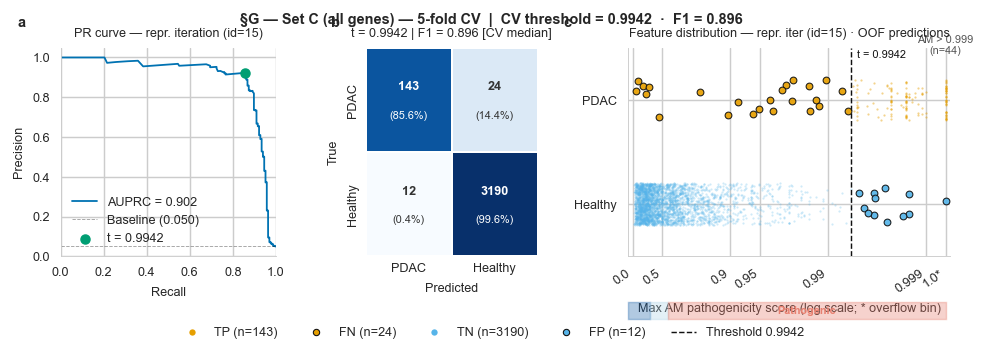

In [ ]:
# ── Performance Figure: PR curve · CM · strip plot — representative iteration ───
# All panels use the same representative bootstrap and its OOF predictions,
# so CM counts equal the strip-plot total.

# ── Load representative bootstrap ───────────────────────────────────────────
try:
    healthy_boot_lazy
except NameError:
    healthy_boot_lazy = pl.scan_parquet(HEALTHY_BOOT_PATH)

_g1k_rep_boot_g = (
    healthy_boot_lazy
    .filter(pl.col('bootstrap_id') == _rep_id_g)
    .select(['sample_id', 'gene_name', 'am_pathogenicity'])
    .collect()
)
_g1k_rep_g    = sorted(_g1k_rep_boot_g['sample_id'].unique().to_list())
_df_rep_g     = pl.concat([
    tcga.select(['sample_id', 'gene_name', 'am_pathogenicity']),
    _g1k_rep_boot_g,
])
_tcga_nohyp_g = sorted([p for p in tcga_ids if p not in _outlier_t1])
_all_rep_g    = np.array(_tcga_nohyp_g + _g1k_rep_g)
_y_rep_g      = np.array([1]*len(_tcga_nohyp_g) + [0]*len(_g1k_rep_g))

# Full feature for representative iteration
_feat_rep_g = compute_feature(_df_rep_g, _all_rep_g, gene_filter_c)

# Re-run 5-fold CV for representative iteration → OOF predictions
_oof_rep_g  = np.zeros(len(_all_rep_g), dtype=int)
_fold_ts_rep = []
for _tr_idx, _val_idx in skf_g.split(_all_rep_g, _y_rep_g):
    _t_fold, _ = find_best_threshold_f1(_feat_rep_g[_tr_idx], _y_rep_g[_tr_idx])
    _oof_rep_g[_val_idx] = (_feat_rep_g[_val_idx] > _t_fold).astype(int)
    _fold_ts_rep.append(_t_fold)
_t_rep_cv_g = float(np.median(_fold_ts_rep))

# PRC uses raw scores; mark OOF operating point
_prec_rep_g, _rec_rep_g, _ = precision_recall_curve(_y_rep_g, _feat_rep_g)
_auprc_rep_g = auc(_rec_rep_g, _prec_rep_g)
_prev_g      = float(_y_rep_g.mean())
_p_pt_g      = precision_score(_y_rep_g, _oof_rep_g, zero_division=0)
_r_pt_g      = recall_score(_y_rep_g,    _oof_rep_g, zero_division=0)

# CM from OOF predictions of representative iteration
_cm_rep_raw_g = np.array([
    [(((_y_rep_g == 1) & (_oof_rep_g == 1)).sum()),   # TP
     (((_y_rep_g == 1) & (_oof_rep_g == 0)).sum())],  # FN
    [(((_y_rep_g == 0) & (_oof_rep_g == 1)).sum()),   # FP
     (((_y_rep_g == 0) & (_oof_rep_g == 0)).sum())],  # TN
], dtype=float)
_cm_rep_norm_g = _cm_rep_raw_g / _cm_rep_raw_g.sum(axis=1, keepdims=True)

# ── Split-plot data (OOF predictions, full population) ───────────────────────
_tp_g_mask = (_y_rep_g == 1) & (_oof_rep_g == 1)
_fn_g_mask = (_y_rep_g == 1) & (_oof_rep_g == 0)
_tn_g_mask = (_y_rep_g == 0) & (_oof_rep_g == 0)
_fp_g_mask = (_y_rep_g == 0) & (_oof_rep_g == 1)

# Alt-3 log transform with overflow bin (matches §C.4 style)
_clip_g   = 1e-5
_lt_g     = lambda f: -np.log10(np.clip(1.0 - np.asarray(f, dtype=float), _clip_g, None))
_x_over_g = float(_lt_g(0.999)) + 0.20
_xv_g     = _lt_g(np.clip(_feat_rep_g, 0, 0.999 - 1e-7))
_xv_g[_feat_rep_g > 0.999] = _x_over_g
_xlim_g      = (-0.05, _x_over_g + 0.05)
_tick_log_g  = [0.0, 0.5, 0.9, 0.95, 0.99, 0.999]
_t_x_g       = float(_lt_g(_t_rep_cv_g))   # CV median threshold on log scale
_rng_g  = np.random.default_rng(42)
_jit_g  = _rng_g.uniform(-0.20, 0.20, len(_y_rep_g))

_cv_f1_med_g = float(np.median([v for r in sub_records_g for v in r['fold_f1']]))  # same as §3 CV median F1
# ── Nature-style figure settings ─────────────────────────────────────────────────────────────────────
_mm = 1 / 25.4  # mm → inches
with mpl.rc_context({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 7,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 2.5,
    'ytick.major.size': 2.5,
    'svg.fonttype': 'none',
}):
    _fig_g = plt.figure(figsize=(183 * _mm, 68 * _mm))
    _gs_g = gridspec.GridSpec(
        1, 3, figure=_fig_g,
        width_ratios=[1, 0.8, 1.5],
        wspace=0.38,
        left=0.04, right=0.99, top=0.88, bottom=0.28,
    )
    _ax_prc_g = _fig_g.add_subplot(_gs_g[0])
    _ax_cm_g  = _fig_g.add_subplot(_gs_g[1])
    _ax_sp_g  = _fig_g.add_subplot(_gs_g[2])

    # ── Bold panel labels ────────────────────────────────────────────────────────────────────
    for _ax_lbl, _lbl in zip([_ax_prc_g, _ax_cm_g, _ax_sp_g], ['a', 'b', 'c']):
        _ax_lbl.text(-0.20, 1.15, _lbl, transform=_ax_lbl.transAxes,
                     fontsize=8, fontweight='bold', va='top', ha='left')

    # ── a) PR curve ──────────────────────────────────────────────────────────────────────────
    _ax_prc_g.plot(_rec_rep_g, _prec_rep_g, color=WONG['blue'], lw=1.0,
                   label=f'AUPRC = {_med_fold_auprc_g:.3f}')
    _ax_prc_g.axhline(_prev_g, color='k', lw=0.5, ls='--', alpha=0.4,
                       label=f'Baseline ({_prev_g:.3f})')
    _ax_prc_g.scatter(_r_pt_g, _p_pt_g, s=25, zorder=5, color=WONG['green'],
                       label=f't = {_t_rep_cv_g:.4f}')
    _ax_prc_g.set_xlim(0, 1)
    _ax_prc_g.set_ylim(0, 1.05)
    _ax_prc_g.set_xlabel('Recall')
    _ax_prc_g.set_ylabel('Precision')
    _ax_prc_g.set_title(f'PR curve \u2014 repr. iteration (id={_rep_id_g})')
    _ax_prc_g.legend(frameon=False, loc='lower left')
    sns.despine(ax=_ax_prc_g)

    # ── b) Confusion matrix ──────────────────────────────────────────────────────────────────
    _f1_rep_g = fbeta_score(_y_rep_g, _oof_rep_g, beta=1, zero_division=0)
    sns.heatmap(
        _cm_rep_norm_g, annot=False, cmap='Blues', vmin=0, vmax=1,
        xticklabels=['PDAC', 'Healthy'], yticklabels=['PDAC', 'Healthy'],
        linewidths=1.0, linecolor='white', ax=_ax_cm_g, cbar=False,
    )
    for _ci_g in range(2):
        for _cj_g in range(2):
            _cnt_g = _cm_rep_raw_g[_ci_g, _cj_g]
            _pct_g = _cm_rep_norm_g[_ci_g, _cj_g] * 100
            _col_g = 'white' if _cm_rep_norm_g[_ci_g, _cj_g] > 0.55 else '#333333'
            _ax_cm_g.text(_cj_g + 0.5, _ci_g + 0.38, f'{_cnt_g:.0f}',
                          ha='center', va='center', fontweight='bold', color=_col_g)
            _ax_cm_g.text(_cj_g + 0.5, _ci_g + 0.65, f'({_pct_g:.1f}%)',
                          ha='center', va='center', fontsize=6, color=_col_g)
    _ax_cm_g.set_xlabel('Predicted')
    _ax_cm_g.set_ylabel('True')
    _ax_cm_g.set_title(f't = {_t_rep_cv_g:.4f} | F1 = {_cv_f1_med_g:.3f} [CV median]')
    _ax_cm_g.tick_params(axis='both', length=0)

    # ── c) Strip plot ─────────────────────────────────────────────────────────────────────────
    for _mask_g, _color_g, _small_g in [
        (_tn_g_mask, COLOR_HEALTHY, True),
        (_tp_g_mask, COLOR_PDAC,    True),
        (_fp_g_mask, COLOR_HEALTHY, False),
        (_fn_g_mask, COLOR_PDAC,    False),
    ]:
        if not _mask_g.any():
            continue
        _y0_g = 1.0 if _color_g == COLOR_PDAC else 0.0
        if _small_g:
            _ax_sp_g.scatter(_xv_g[_mask_g], _y0_g + _jit_g[_mask_g],
                             c=_color_g, s=1.5,
                             alpha=0.45 if _color_g == COLOR_PDAC else 0.28,
                             linewidths=0, zorder=2)
        else:
            _ax_sp_g.scatter(_xv_g[_mask_g], _y0_g + _jit_g[_mask_g],
                             c=_color_g, s=14, alpha=0.92,
                             linewidths=0.6, edgecolors='#111111', zorder=5)

    _ax_sp_g.axvline(_t_x_g, color='#111111', lw=0.8, ls='--')
    _ax_sp_g.annotate(f'  t = {_t_rep_cv_g:.4f}',
                       xy=(_t_x_g, 1.38), fontsize=6, color='#111111',
                       ha='left', va='bottom')

    _ax_sp_g.set_ylim(-0.5, 1.5)
    _ax_sp_g.set_yticks([0, 1])
    _ax_sp_g.set_yticklabels(['Healthy', 'PDAC'])
    _ax_sp_g.set_xlim(*_xlim_g)
    _ax_sp_g.set_xticks([float(_lt_g(f)) for f in _tick_log_g] + [_x_over_g])
    _ax_sp_g.set_xticklabels([str(f) for f in _tick_log_g] + ['1.0*'],
                               rotation=35, ha='right')
    _ax_sp_g.set_xlabel('Max AM pathogenicity score (log scale; * overflow bin)')
    sns.despine(ax=_ax_sp_g)

    _n_over_g = int((_feat_rep_g > 0.999).sum())
    _ax_sp_g.text(_x_over_g, 1.42, f'AM > 0.999\n(n={_n_over_g})',
                  ha='center', va='bottom', fontsize=6, color='#555555',
                  clip_on=False)

    # ── AM-zone colour bar (below xlabel, only Pathogenic labelled) ──────────────
    from matplotlib.patches import Rectangle as _Rect
    _tr_z = _ax_sp_g.get_xaxis_transform()
    _xb_z = float(_lt_g(AM_BENIGN_MAX))
    _xp_z = float(_lt_g(AM_PATH_MIN))
    _ybot_z = -0.30
    _htz = 0.08
    for _x0z, _x1z, _cz in [
        (_ax_sp_g.get_xlim()[0], _xb_z,     _C_BENIGN),
        (_xb_z,                  _xp_z,     _C_UNCERTAIN),
        (_xp_z,                  _x_over_g, _C_PATH),
    ]:
        _vx0 = max(_x0z, _ax_sp_g.get_xlim()[0])
        _vx1 = min(_x1z, _ax_sp_g.get_xlim()[1])
        if _vx0 >= _vx1:
            continue
        _ax_sp_g.add_patch(_Rect((_vx0, _ybot_z), _vx1 - _vx0, _htz,
            transform=_tr_z, color=_cz, alpha=0.35, clip_on=False, zorder=2))
    _ax_sp_g.text((_xp_z + _x_over_g) / 2, _ybot_z + _htz / 2, 'Pathogenic',
                  transform=_tr_z, ha='center', va='center', fontsize=6,
                  color=_C_PATH, fontweight='bold', clip_on=False)

    # Legend
    _n_tp_g = int(_tp_g_mask.sum()); _n_fn_g = int(_fn_g_mask.sum())
    _n_tn_g = int(_tn_g_mask.sum()); _n_fp_g = int(_fp_g_mask.sum())
    _leg_g = [
        Line2D([0],[0], marker='o', color='none', mfc=COLOR_PDAC, mec='none',
               mew=0, markersize=3.5, label=f'TP (n={_n_tp_g})'),
        Line2D([0],[0], marker='o', color='none', mfc=COLOR_PDAC, mec='#111111',
               mew=0.6, markersize=3.5, label=f'FN (n={_n_fn_g})'),
        Line2D([0],[0], marker='o', color='none', mfc=COLOR_HEALTHY, mec='none',
               mew=0, markersize=3.5, label=f'TN (n={_n_tn_g})'),
        Line2D([0],[0], marker='o', color='none', mfc=COLOR_HEALTHY, mec='#111111',
               mew=0.6, markersize=3.5, label=f'FP (n={_n_fp_g})'),
        Line2D([0],[0], color='#111111', lw=0.8, ls='--',
               label=f'Threshold {_t_rep_cv_g:.4f}'),
    ]
    _ax_sp_g.set_title(
        f'Feature distribution \u2014 repr. iter (id={_rep_id_g}) \u00b7 OOF predictions'
    )
    _fig_g.legend(handles=_leg_g, frameon=False, ncol=5,
                  loc='lower center', bbox_to_anchor=(0.5, 0.01))

    _fig_g.suptitle(
        f'\u00a7G \u2014 Set C (all genes) \u2014 5-fold CV  |  '
        f'CV threshold = {_t_rep_cv_g:.4f}  \u00b7  F1 = {_cv_f1_med_g:.3f}',
        fontsize=8, fontweight='bold',
    )

    fig_name = 'KO5_G_allgenes_cv'
    plt.savefig(out_dir / f'{fig_name}.pdf', dpi=300)
    plt.savefig(out_dir / f'{fig_name}.png', dpi=300)
    with mpl.rc_context({'svg.fonttype': 'none'}):
        plt.savefig(out_dir / f'{fig_name}.svg', bbox_inches='tight')
    print('Saved to', out_dir.resolve())
    plt.show()


## 3. Key ML Metrics Table

Cross-validated performance metrics (500 folds: 100 bootstrap resamples × 5-fold CV). All values are medians; 95% CIs span the 2.5th–97.5th percentiles of the fold distribution.

In [22]:
from great_tables import GT, md as gtmd, style, loc

# ── CV values from 500 folds (fold_* keys in sub_records_g) ─────────────────
_cv_f1    = [v for r in sub_records_g for v in r['fold_f1']]
_cv_prec  = [v for r in sub_records_g for v in r['fold_prec']]
_cv_rec   = [v for r in sub_records_g for v in r['fold_rec']]
_cv_spec  = [v for r in sub_records_g for v in r['fold_spec']]
_cv_auprc = [v for r in sub_records_g for v in r['fold_auprc']]
_cv_roc   = [v for r in sub_records_g for v in r['fold_auc_roc']]
_cv_roc_h_raw = [v for r in sub_records_h for v in r['fold_auc_roc']]
_cv_roc_h = ([1 - v for v in _cv_roc_h_raw]
             if float(np.median(_cv_roc_h_raw)) < 0.5 else _cv_roc_h_raw)

def _cv_med(vals): return f'{float(np.median(vals)):.3f}'
def _cv_ci(vals):
    return (f'{float(np.percentile(vals, 2.5)):.3f}'
            f'–{float(np.percentile(vals, 97.5)):.3f}')

_rows_t1 = [
    ('Threshold (F₁)',  f'{_t_c3:.4f}',
     f'{float(np.percentile([r["t"] for r in sub_records_c3], 2.5)):.4f}'
     f'–{float(np.percentile([r["t"] for r in sub_records_c3], 97.5)):.4f}'),
    ('F1',           _cv_med(_cv_f1),    _cv_ci(_cv_f1)),
    ('Precision',    _cv_med(_cv_prec),  _cv_ci(_cv_prec)),
    ('Recall',       _cv_med(_cv_rec),   _cv_ci(_cv_rec)),
    ('Specificity',  _cv_med(_cv_spec),  _cv_ci(_cv_spec)),
    ('AUPRC',        _cv_med(_cv_auprc), _cv_ci(_cv_auprc)),
    ('AUROC',      _cv_med(_cv_roc),   _cv_ci(_cv_roc)),
    ('AUROC (Classical vs Basal-like)', _cv_med(_cv_roc_h), _cv_ci(_cv_roc_h)),
]

df_t1 = pl.DataFrame({
    'Metric': [r[0] for r in _rows_t1],
    'Median': [r[1] for r in _rows_t1],
    'CI':     [r[2] for r in _rows_t1],
})

BOLD_T1  = [1, 5, 6]     # F1, AUPRC, AUROC (row 7 = Classical vs Basal-like AUROC, not bolded)
LIGHT_T1 = [0]            # Threshold

display(
    GT(df_t1)
    .tab_header(
        title    = gtmd('**Set C — AlphaMissense Threshold Classifier: CV Performance**'),
        subtitle = gtmd(
            f'Maximum AlphaMissense score · F₁‑optimal threshold · '
            f'all genes · 5-fold CV (100 subagging × 5 folds)'
        ),
    )
    .cols_label(Metric='', Median='CV median', CI='95 % CI (N = 500)')
    .cols_align(align='left',  columns=['Metric'])
    .cols_align(align='right', columns=['Median', 'CI'])
    .cols_width({'Metric': '160px', 'Median': '110px', 'CI': '160px'})
    .tab_style(style=style.text(weight='bold'),    locations=loc.body(rows=BOLD_T1))
    .tab_style(style=style.text(color='#888888'), locations=loc.body(rows=LIGHT_T1))
    .tab_source_note(gtmd(
        'CV 95 % CI: 2.5th–97.5th percentile of 500 per-fold values '
        '(100 × 5 folds). '
        'Threshold and MCC: §C.3 subagging median (N = 100).'
    ))
)

GT(_tbl_data=shape: (8, 3)
┌─────────────────────────────────┬────────┬───────────────┐
│ Metric                          ┆ Median ┆ CI            │
│ ---                             ┆ ---    ┆ ---           │
│ str                             ┆ str    ┆ str           │
╞═════════════════════════════════╪════════╪═══════════════╡
│ Threshold (F₁)                  ┆ 0.9942 ┆ 0.9942–0.9946 │
│ F1                              ┆ 0.896  ┆ 0.794–0.954   │
│ Precision                       ┆ 0.927  ┆ 0.833–1.000   │
│ Recall                          ┆ 0.909  ┆ 0.758–0.912   │
│ Specificity                     ┆ 0.997  ┆ 0.991–1.000   │
│ AUPRC                           ┆ 0.902  ┆ 0.769–0.989   │
│ AUROC                           ┆ 0.959  ┆ 0.936–0.999   │
│ AUROC (Classical vs Basal-like… ┆ 0.552  ┆ 0.331–0.776   │
└─────────────────────────────────┴────────┴───────────────┘, _body=<great_tables._gt_data.Body object at 0x0000020EC85EF8C0>, _boxhead=Boxhead([ColInfo(var='Metric', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width='160px'), ColInfo(var='Median', type=<ColInfoTypeEnum.default: 1>, column_label='CV median', column_align='right', column_width='110px'), ColInfo(var='CI', type=<ColInfoTypeEnum.default: 1>, column_label='95\u202f% CI (N\u202f=\u202f500)', column_align='right', column_width='160px')]), _stub=<great_tables._gt_data.Stub object at 0x0000020EC85EF620>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Set C — AlphaMissense Threshold Classifier: CV Performance**'), subtitle=Md(text='Maximum AlphaMissense score · F₁‑optimal threshold · all genes · 5-fold CV (100 subagging × 5 folds)'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000020EC85EFCB0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000020EC85E3750>, _source_notes=[Md(text='CV\u202f95\u202f%\u202fCI: 2.5th–97.5th percentile of 500 per-fold values (100\u202f×\u202f5 folds). Threshold and MCC: §C.3 subagging median (N\u202f=\u202f100).')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Metric', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Metric', rownum=5, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Metric', rownum=6, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Median', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Median', rownum=5, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='Median', rownum=6, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[1, 5, 6], mask=None), grpname=None, colname='CI', rownum=1, colnum=None, styles=[CellStyl

## 4. Classification Breakdown Table

In [23]:
# ── Section 4: Great Tables — Classification breakdown ──────────────────────────
from great_tables import GT, md, style, loc

_cats1    = df_ind_c['Category'].to_list()
_main1    = [i for i, c in enumerate(_cats1) if c == c.strip()]
_sub1     = [i for i, c in enumerate(_cats1) if c != c.strip()]

(
    GT(df_ind_c)
    .tab_header(
        title    = md('**PDAC Classification Breakdown — Set C**'),
        subtitle = md(
            f'Maximum AlphaMissense score · F₁‑optimal threshold = **{_t_c3:.4f}** · '
            f'all {n_genes_c:,} genes · '
            f'167 PDAC (1 hypermutator excl.) vs 3 202 healthy'
        ),
    )
    .cols_label(**{
        'Category':    '',
        'n':           'n',
        '%':           '%',
        '95% CI':      '95 % CI',
    })
    .cols_align(align='left',  columns=['Category'])
    .cols_align(align='right', columns=['n', '%', '95% CI'])
    .cols_width({'Category': '270px', 'n': '45px', '%': '55px', '95% CI': '115px'})
    .fmt_integer(columns=['n'])
    .tab_style(
        style     = style.text(weight='bold'),
        locations = loc.body(rows=_main1),
    )
    .tab_style(
        style     = style.text(color='#555555', style='italic'),
        locations = loc.body(rows=_sub1),
    )
    .tab_source_note(
        source_note=md(
            'n = subagging median (N = 100) · '
            '95 % CI = 2.5th– 97.5th percentile · '
            'Subagging: same 3 202 healthy individuals, '
            'mutations re-sampled per iteration (stochastic-k); PDAC patients fixed.'
        )
    )
)


GT(_tbl_data=shape: (8, 4)
┌─────────────────────────────────┬──────┬──────┬───────────┐
│ Category                        ┆ n    ┆ %    ┆ 95% CI    │
│ ---                             ┆ ---  ┆ ---  ┆ ---       │
│ str                             ┆ i64  ┆ str  ┆ str       │
╞═════════════════════════════════╪══════╪══════╪═══════════╡
│ All PDAC patients               ┆ 167  ┆ 100% ┆ —         │
│ True Positives                  ┆ 143  ┆ 86%  ┆ 141–143   │
│ False Negatives                 ┆ 24   ┆ 14%  ┆ 24–26     │
│  With pathogenic mutation (max… ┆ 18   ┆ 75%  ┆ 18–20     │
│  No pathogenic mutation (max A… ┆ 6    ┆ 25%  ┆ 6–6       │
│ All Healthy individuals         ┆ 3202 ┆ 100% ┆ —         │
│ False Positives                 ┆ 12   ┆ 0%   ┆ 6–18      │
│ True Negatives                  ┆ 3190 ┆ 100% ┆ 3184–3196 │
└─────────────────────────────────┴──────┴──────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x0000020EC8597A80>, _boxhead=Boxhead([ColInfo(var='Category', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width='270px'), ColInfo(var='n', type=<ColInfoTypeEnum.default: 1>, column_label='n', column_align='right', column_width='45px'), ColInfo(var='%', type=<ColInfoTypeEnum.default: 1>, column_label='%', column_align='right', column_width='55px'), ColInfo(var='95% CI', type=<ColInfoTypeEnum.default: 1>, column_label='95\u2009%\u2009CI', column_align='right', column_width='115px')]), _stub=<great_tables._gt_data.Stub object at 0x0000020EC26EB890>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**PDAC Classification Breakdown — Set C**'), subtitle=Md(text='Maximum AlphaMissense score · F₁‑optimal threshold = **0.9942** · all 13,797 genes · 167 PDAC (1 hypermutator excl.) vs 3\u202f202 healthy'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x0000020EC85E3ED0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000020EC8597CE0>, _source_notes=[Md(text='n\u2009=\u2009subagging median (N\u2009=\u2009100) · 95\u2009%\u2009CI\u2009=\u20092.5th– 97.5th percentile · Subagging: same 3\u202f202 healthy individuals, mutations re-sampled per iteration (stochastic-k); PDAC patients fixed.')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=1, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=2, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=5, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=6, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 1, 2, 5, 6, 7], mask=None), grpname=None, colname='Category', rownum=7, colnum=None, styles=[CellStyleText(color=None, font=None, size=None

## 5. Highly Pathogenic Mutations Table

Hotspot residues and genes with AM above the F₁-optimal threshold. Rarely-mutated genes are collapsed into a summary row.

In [19]:
# ── KO5 Table 3: formatted table ─────────────────────────────────────────────
_cats2 = df_mut_c['Category'].to_list()
_main2 = [i for i, c in enumerate(_cats2) if c == c.strip()]
_sub2  = [i for i, c in enumerate(_cats2) if c != c.strip()]

# ── Section 5: Great Tables — Highly pathogenic mutations ───────────────────────
from great_tables import GT, md, style, loc


(
    GT(df_mut_c)
    .tab_header(
        title    = md('**Highly Pathogenic Mutations in Hotspots and Genes**'),
        subtitle = md(
            f'AM score > {_t_c3:.4f} (F₁ threshold) · all genes · '
            f'TP patients: n = {_N_TP_ref} · '
            'hotspot = position in ≥2 patients · 1 hypermutator excl.'
        ),
    )
    .cols_label(**{
        'Category':     '',
        'N':            'N',
        'Patients (n)': 'Patients',
        '% of PDAC':    '% of PDAC',
        'Details':      'Details',
    })
    .cols_align(align='left',  columns=['Category', 'Details'])
    .cols_align(align='right', columns=['N', 'Patients (n)', '% of PDAC'])
    .fmt_integer(columns=['N', 'Patients (n)'])
    .tab_style(
        style     = style.text(weight='bold'),
        locations = loc.body(rows=_main2),
    )
    .tab_style(
        style     = style.text(color='#555555', style='italic'),
        locations = loc.body(rows=_sub2),
    )
    .tab_source_note(
        source_note=md(
            'N = number of hotspot positions (hotspot rows) or unique genes (gene rows). '
            'Hotspot patients: union across positions (patients may overlap across rows). '
            'Gene patients: patients with AM > threshold in that gene (all positions).'
        )
    )
)


GT(_tbl_data=shape: (6, 5)
┌────────────────────────────┬─────┬──────────────┬───────────┬─────────────────────────────────┐
│ Category                   ┆ N   ┆ Patients (n) ┆ % of PDAC ┆ Details                         │
│ ---                        ┆ --- ┆ ---          ┆ ---       ┆ ---                             │
│ str                        ┆ i64 ┆ i64          ┆ str       ┆ str                             │
╞════════════════════════════╪═════╪══════════════╪═══════════╪═════════════════════════════════╡
│ Hotspots                   ┆ 9   ┆ 114          ┆ 68%       ┆ —                               │
│  In canonical driver genes ┆ 8   ┆ 110          ┆ 65%       ┆ KRAS G12, KRAS Q61, TP53 R248,… │
│  In driver-like genes      ┆ 1   ┆ 5            ┆ 3%        ┆ GNAS R844                       │
│ Genes                      ┆ 150 ┆ 142          ┆ 85%       ┆ —                               │
│  Canonical driver genes    ┆ 3   ┆ 113          ┆ 67%       ┆ KRAS, TP53, SMAD4               │
│  Driver-like genes         ┆ 20  ┆ 25           ┆ 15%       ┆ TAOK2, KCNA4, FLNA, LRP1, GRIN… │
└────────────────────────────┴─────┴──────────────┴───────────┴─────────────────────────────────┘, _body=<great_tables._gt_data.Body object at 0x000002744769F620>, _boxhead=Boxhead([ColInfo(var='Category', type=<ColInfoTypeEnum.default: 1>, column_label='', column_align='left', column_width=None), ColInfo(var='N', type=<ColInfoTypeEnum.default: 1>, column_label='N', column_align='right', column_width=None), ColInfo(var='Patients (n)', type=<ColInfoTypeEnum.default: 1>, column_label='Patients', column_align='right', column_width=None), ColInfo(var='% of PDAC', type=<ColInfoTypeEnum.default: 1>, column_label='% of PDAC', column_align='right', column_width=None), ColInfo(var='Details', type=<ColInfoTypeEnum.default: 1>, column_label='Details', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000002744769F380>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Highly Pathogenic Mutations in Hotspots and Genes**'), subtitle=Md(text='AM score > 0.9942 (F₁ threshold) · all genes · TP patients: n = 143 · hotspot = position in ≥2 patients · 1 hypermutator excl.'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000002744769FA10>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x0000027447319BD0>, _source_notes=[Md(text='N = number of hotspot positions (hotspot rows) or unique genes (gene rows). Hotspot patients: union across positions (patients may overlap across rows). Gene patients: patients with AM > threshold in that gene (all positions).')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=[0, 3], mask=None), grpname=None, colname='Category', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 3], mask=None), grpname=None, colname='Category', rownum=3, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 3], mask=None), grpname=None, colname='N', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 3], mask=None), grpname=None, colname='N', rownum=3, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 3], mask=None), grpname=None, colname='Patients (n)', rownum=0, colnum=None, s

## 6. Mutation Landscape Figure

9 hotspot rows (1 per trigger residue: canonical drivers + GNAS) + 21 gene rows (canonical non-hotspot hits + driver-like genes). Patients are cascade-ordered top-left → bottom-right by mutation priority. True positives are left of the dotted divider; false negatives to the right. Hit counts per row shown on the right margin.

In [25]:
# ── Row definitions from the highly pathogenic mutations table ──────────────────
# Hotspot rows: canonical driver residues + GNAS R844 (from _h_labels)
_hs_row_labels = (
    _sort_labels(_h_labels['Canonical driver'], 'Canonical driver')
    + _sort_labels(_h_labels['Driver-like'],   'Driver-like')
)   # e.g. ['KRAS G12', 'KRAS G13', ..., 'GNAS R844']

# Gene rows: canonical non-hotspot + all driver-like
_gn_row_labels = (
    _sort_labels(_g_labels['Canonical driver'], 'Canonical driver')
    + _sort_labels(_g_labels['Driver-like'],    'Driver-like')
)

# Convert hotspot display labels "GENE POS" → residue_label "GENE_POS"
_hs_res_labels = [l.replace(' ', '_') for l in _hs_row_labels]

print(f'Hotspot rows : {len(_hs_row_labels)} → {_hs_row_labels}')
print(f'Gene rows    : {len(_gn_row_labels)} → {_gn_row_labels}')

# ── Build patient list: all PDAC (excl. hypermutator), then hypermutator ──────
_all_pdac   = [p for p in tcga_ids if p not in _outlier_t1]  # 166 patients

# ── Prepare mutation data for all PDAC patients ───────────────────────────────
_df_all_pdac = (
    tcga
    .filter(pl.col('sample_id').is_in(_all_pdac))
    .drop_nulls(['am_pathogenicity', 'protein_variant'])
    .with_columns(
        pl.col('protein_variant')
        .map_elements(_residue_c, return_dtype=pl.Utf8)
        .alias('residue')
    )
    .with_columns(
        (pl.col('gene_name') + '_' + pl.col('residue')).alias('residue_label')
    )
)

# ── Hit matrices (rows × patients) ───────────────────────────────────────────

# Max AM per patient across all genes (for FN sub-sorting)
_max_am_pid = {
    r['sample_id']: r['max_am']
    for r in tcga
    .group_by('sample_id')
    .agg(pl.col('am_pathogenicity').max().alias('max_am'))
    .iter_rows(named=True)
}
N_HS = len(_hs_res_labels)
N_GN = len(_gn_row_labels)
N_PT = len(_all_pdac)

_pid_idx = {p: i for i, p in enumerate(_all_pdac)}

hs_mat = np.full((N_HS, N_PT), np.nan)
for row in (
    _df_all_pdac
    .filter(pl.col('residue_label').is_in(_hs_res_labels))
    .group_by(['sample_id', 'residue_label'])
    .agg(pl.col('am_pathogenicity').max().alias('am'))
    .iter_rows(named=True)
):
    ci = _pid_idx.get(row['sample_id'])
    if ci is not None:
        ri = _hs_res_labels.index(row['residue_label'])
        hs_mat[ri, ci] = row['am']

gn_mat = np.full((N_GN, N_PT), np.nan)
for row in (
    _df_all_pdac
    .filter(pl.col('gene_name').is_in(_gn_row_labels))
    .filter(~pl.col('residue_label').is_in(list(hotspot_set)))
    .group_by(['sample_id', 'gene_name'])
    .agg(pl.col('am_pathogenicity').max().alias('am'))
    .iter_rows(named=True)
):
    ci = _pid_idx.get(row['sample_id'])
    if ci is not None:
        ri = _gn_row_labels.index(row['gene_name'])
        gn_mat[ri, ci] = row['am']


# ── Cascade sort (non-hypermutator patients) ──────────────────────────────────
def _cascade_key_5(i):
    for r in range(N_HS):
        am = hs_mat[r, i]
        if not np.isnan(am) and am > _t_c3:
            return (r, -am)
    for r in range(N_GN):
        am = gn_mat[r, i]
        if not np.isnan(am) and am > _t_c3:
            return (N_HS + 1 + r, -am)
    # FN: sub-sort by whether any mutation is pathogenic
    pid = _all_pdac[i]
    max_am = _max_am_pid.get(pid, 0.0)
    if max_am >= AM_PATH_MIN:
        return (9998, -max_am)  # FN with pathogenic mutation
    return (9999, 0.0)           # FN with no pathogenic mutation

_sorted_cols = sorted(range(N_PT), key=_cascade_key_5)
# Index of first FN patient in the sorted column order
_tp_fn_split = next(
    (i for i, c in enumerate(_sorted_cols) if _cascade_key_5(c)[0] >= 9998),
    N_PT,  # all TP if no FN
)

hs_plot = hs_mat[:, _sorted_cols]
gn_plot = gn_mat[:, _sorted_cols]
_sorted_pids_plot = [_all_pdac[i] for i in _sorted_cols]

N_PT_PLOT = len(_sorted_pids_plot)

# Combined matrix (separator row between hotspot and gene blocks)
_sep_row  = np.full((1, N_PT_PLOT), np.nan)
full_plot = np.vstack([hs_plot, _sep_row, gn_plot])
SEP_IDX   = N_HS

# Hotspot circle hits: AM > _t_c3 (exclude hypermutator column from count)
_hs_hit_rows, _hs_hit_cols = np.where(hs_plot > _t_c3)
_gn_hit_rows, _gn_hit_cols = np.where(gn_plot > _t_c3)
# Adjusted col positions in full_plot
_hs_hit_cols_adj = _hs_hit_cols
_gn_hit_cols_adj = _gn_hit_cols

# Patient counts per row (excl. hypermutator)
_hs_n_pats = [int(np.sum(hs_plot[r, :] > _t_c3)) for r in range(N_HS)]
_gn_n_pats = [int(np.sum(gn_plot[r, :] > _t_c3)) for r in range(N_GN)]

print(f'Matrix shape: {full_plot.shape}  ({N_HS} hotspot + 1 sep + {N_GN} gene rows × {N_PT_PLOT} patients)')
print(f'Hotspot hits: {len(_hs_hit_rows)}  |  Gene hits: {len(_gn_hit_rows)}')

Hotspot rows : 9 → ['KRAS G12', 'KRAS Q61', 'TP53 R248', 'TP53 H179', 'TP53 G245', 'TP53 S241', 'TP53 R273', 'SMAD4 R361', 'GNAS R844']
Gene rows    : 20 → ['TP53', 'SMAD4', 'TAOK2', 'FLNA', 'GRIN2D', 'LRP1', 'KCNA4', 'KCNA6', 'HSPA5', 'KCNH7', 'TGFBR2', 'ATP2A1', 'TRPC6', 'ADNP', 'ATRNL1', 'KCNB2', 'APBA2', 'COL1A2', 'PLXNA2', 'TTN']
Matrix shape: (30, 167)  (9 hotspot + 1 sep + 20 gene rows × 167 patients)
Hotspot hits: 130  |  Gene hits: 41


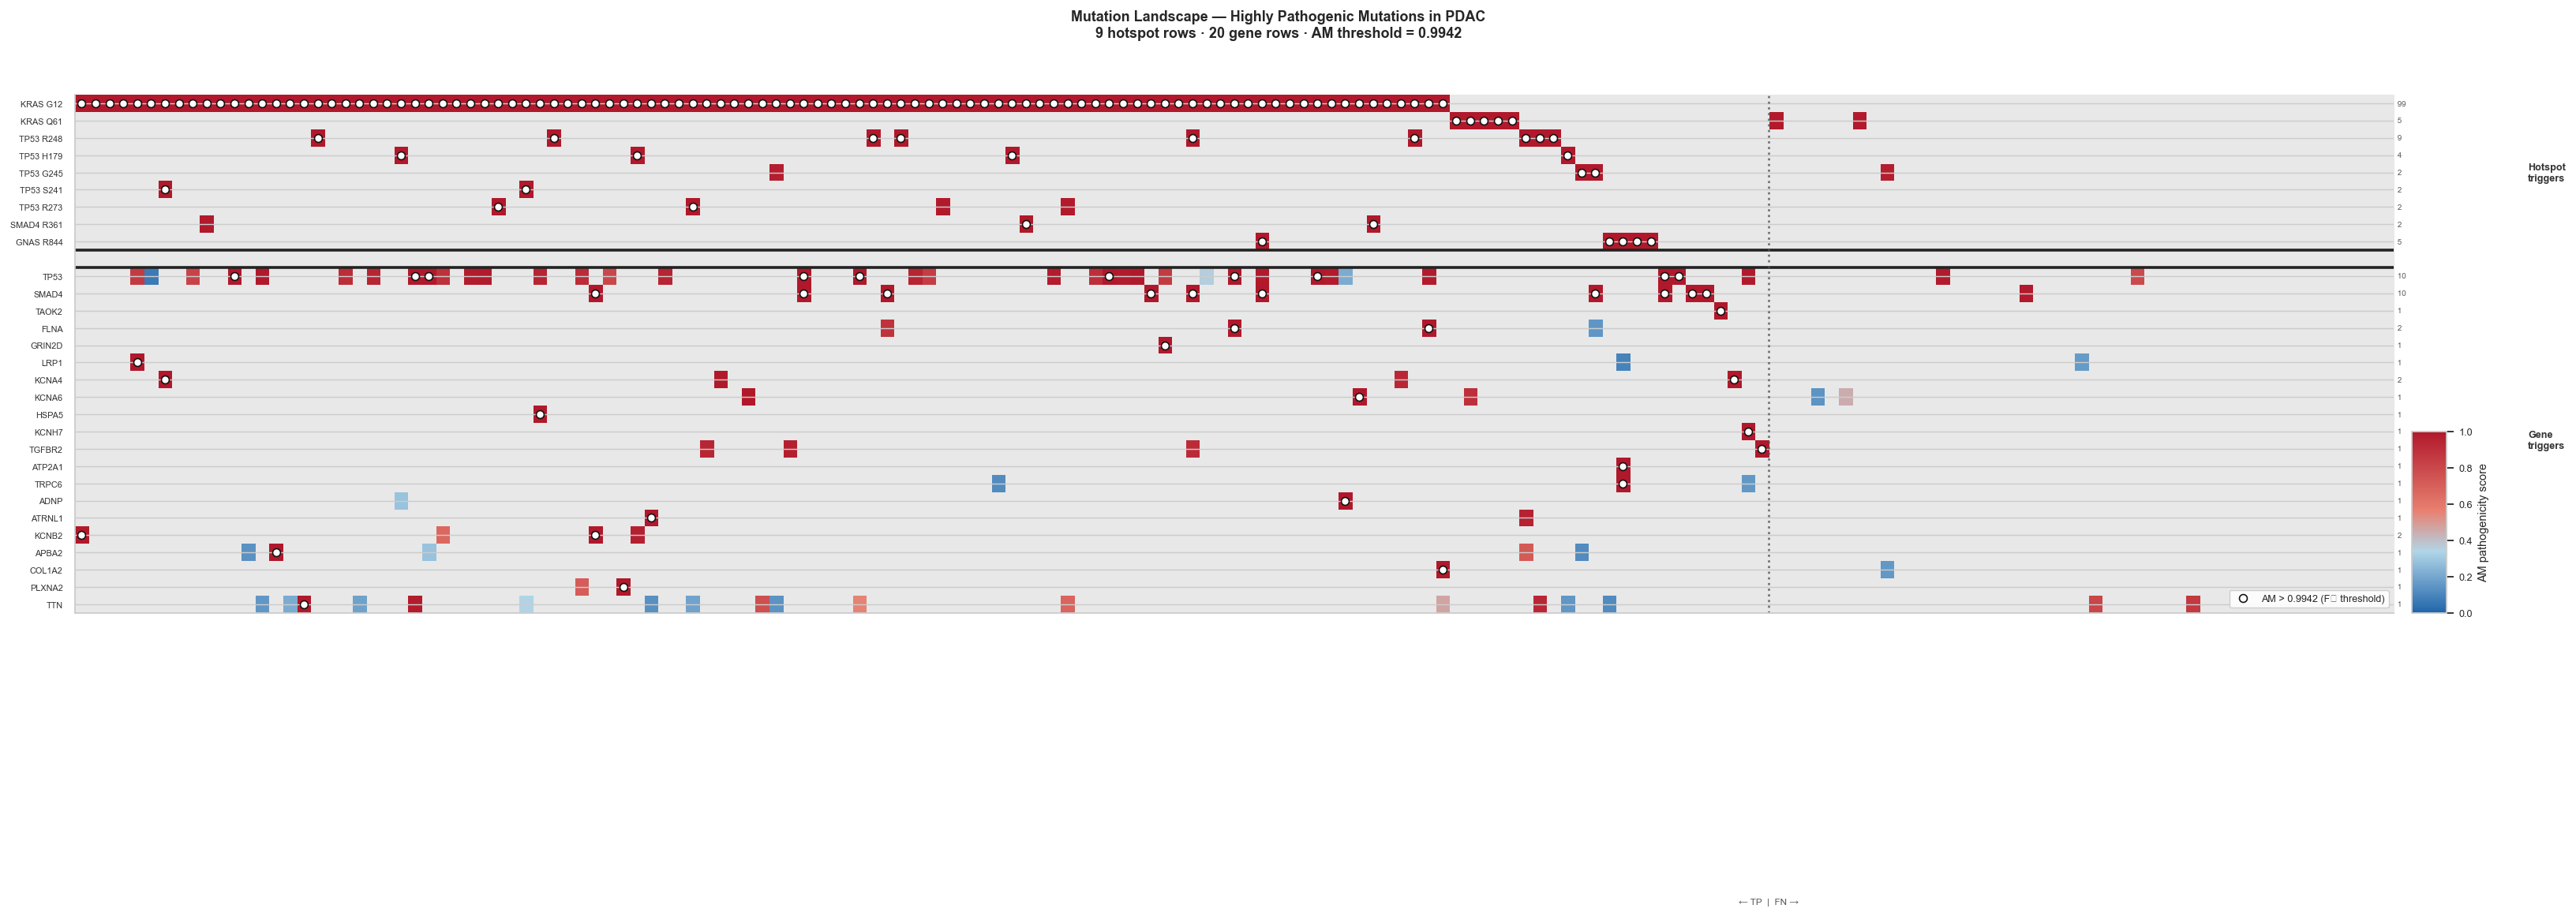

Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


In [26]:
# ── Figure ───────────────────────────────────────────────────────────────────
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D

_fig_w = max(18, N_PT_PLOT * 0.12 + 5)
_fig_h = max(6,  (N_HS + N_GN + 1) * 0.32 + 1.2)
_fig5, _ax5 = plt.subplots(figsize=(_fig_w, _fig_h))

_im5 = _ax5.imshow(full_plot, aspect='auto', cmap=cmap_am, vmin=0, vmax=1,
                    interpolation='none')

# Separator line between hotspot and gene blocks
_ax5.axhline(SEP_IDX - 0.5, color='#222222', lw=2.0)
_ax5.axhline(SEP_IDX + 0.5, color='#222222', lw=2.0)

# Circle markers: AM > _t_c3
_ax5.plot(_hs_hit_cols_adj, _hs_hit_rows, 'o', ms=5.5, color='white',
          markeredgewidth=0.9, markeredgecolor='#111111', linestyle='none', zorder=5)
_ax5.plot(_gn_hit_cols_adj, _gn_hit_rows + SEP_IDX + 1, 'o', ms=5.5, color='white',
          markeredgewidth=0.9, markeredgecolor='#111111', linestyle='none', zorder=5)


# Vertical line separating TP patients (left) from FN patients (right)
if _tp_fn_split < N_PT:
    _ax5.axvline(_tp_fn_split - 0.5, color='#555555', lw=1.5, ls=':', alpha=0.8)
    _ax5.text(_tp_fn_split - 0.5, -0.55, '← TP  |  FN →',
              ha='center', va='top', fontsize=6.5, color='#555555',
              transform=_ax5.get_xaxis_transform(), clip_on=False)

# Y-axis labels
_ytick_pos = list(range(N_HS)) + list(range(SEP_IDX + 1, SEP_IDX + 1 + N_GN))
_ytick_lbl = _hs_row_labels + _gn_row_labels
_ytick_clr = ['#333333'] * (len(_hs_row_labels) + len(_gn_row_labels))

_ax5.set_yticks(_ytick_pos)
_ax5.set_yticklabels(_ytick_lbl, fontsize=6)
for tick, clr in zip(_ax5.get_yticklabels(), _ytick_clr):
    tick.set_color(clr)

# Patient count annotations (right side)
for r in range(N_HS):
    _ax5.text(N_PT_PLOT - 0.4, r, f' {_hs_n_pats[r]}', va='center',
              fontsize=5.5, color='#555555', clip_on=False,
              transform=_ax5.transData)
for r in range(N_GN):
    _ax5.text(N_PT_PLOT - 0.4, SEP_IDX + 1 + r, f' {_gn_n_pats[r]}', va='center',
              fontsize=5.5, color='#555555', clip_on=False,
              transform=_ax5.transData)

# Colourbar
_cax5 = _ax5.inset_axes([1.008, 0, 0.015, 0.35])
_cb5  = _fig5.colorbar(_im5, cax=_cax5)
_cb5.set_label('AM pathogenicity score', fontsize=8, labelpad=4)
_cb5.ax.tick_params(labelsize=7)

# Section labels
_lx = 1.058
_ax5.text(_lx, 1 - N_HS / (2 * (N_HS + 1 + N_GN)), 'Hotspot\ntriggers',
          va='center', ha='left', fontsize=7, fontweight='bold',
          color='#333333', transform=_ax5.transAxes, clip_on=False)
_ax5.text(_lx, 1 - (N_HS + 1 + N_GN / 2) / (N_HS + 1 + N_GN), 'Gene\ntriggers',
          va='center', ha='left', fontsize=7, fontweight='bold',
          color='#333333', transform=_ax5.transAxes, clip_on=False)

# X-axis
_ax5.set_xticks([])

# Legend
_leg5 = [
    Line2D([0],[0], marker='o', color='w', mfc='white', mec='#111111',
           mew=0.9, ms=5.5, ls='none',
           label=f'AM > {_t_c3:.4f} (F₁ threshold)'),
]
_ax5.legend(handles=_leg5, loc='lower right', fontsize=7,
            frameon=True, framealpha=0.9, edgecolor='#cccccc')

_fig5.suptitle(
    f'Mutation Landscape — Highly Pathogenic Mutations in PDAC\n'
    f'{N_HS} hotspot rows · {N_GN} gene rows · '
    f'AM threshold = {_t_c3:.4f}',
    fontsize=10, fontweight='bold', y=0.99,
)
sns.despine(ax=_ax5)
plt.tight_layout(rect=[0, 0, 1, 0.97])

_figname5 = 'KO5_mutation_landscape'
plt.savefig(out_dir / f'{_figname5}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(out_dir / f'{_figname5}.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_dir / f'{_figname5}.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())

## 7. Score Distributions & Effect Size

AlphaMissense score distributions (PDAC somatic vs 1000 Genomes germline) and CLES lower bound for 4 canonical driver genes, GNAS, and 19 driver-like genes.

In [20]:
# ── Gene set for Section 7 ────────────────────────────────────────────────────
# 4 canonical drivers (top, bold) + GNAS (5th) + 19 driver-like (from Table 5)
_driver_set7 = set(DRIVER_GENES)   # for bold labels

_gnas_label  = ['GNAS']
_dlike_all    = _sort_labels(_g_labels['Driver-like'], 'Driver-like')

_genes7      = DRIVER_GENES + _gnas_label + _dlike_all
_n7          = len(_genes7)
SEP7         = _n7 - len(DRIVER_GENES) - 0.5  # separator above GNAS (between GNAS and canonical drivers)

print(f'Section 7 genes ({_n7} total):')
print(f'  Canonical : {DRIVER_GENES}')
print(f'  GNAS      : {_gnas_label}')
print(f'  Driver-like: {_dlike_all}')

# ── Score arrays per gene ─────────────────────────────────────────────────────
_rows7 = list(reversed(_genes7))   # reversed so rank-1 at top in horizontal plot

# Full 1000G data (not bootstrap-subsampled) for distribution plot
_g1000_full_s7 = (
    pl.read_parquet(REPO_DATA / 'merged_tcga_1000G.parquet',
                    columns=['source', 'sample_id', 'gene_name', 'am_pathogenicity'])
    .filter(pl.col('source') == '1000G')
    .drop('source')
    .drop_nulls('am_pathogenicity')
)

def _get_scores(df, gene_list):
    out = {}
    for row in (
        df.filter(pl.col('gene_name').is_in(gene_list))
        .filter(pl.col('am_pathogenicity').is_not_null())
        .group_by('gene_name')
        .agg(pl.col('am_pathogenicity').alias('scores'))
        .iter_rows(named=True)
    ):
        out[row['gene_name']] = np.array(row['scores'])
    return out

_pdac_sc7    = _get_scores(tcga,  _genes7)
_healthy_sc7 = _get_scores(_g1000_full_s7, _genes7)

# CLES lower bound from ranking_table (for driver-like + GNAS)
_cles_map = {
    r['gene_name']: r['cles_lb']
    for r in ranking_table.filter(pl.col('gene_name').is_in(_genes7)).iter_rows(named=True)
}
# For canonical drivers, use CLES from ranking_table or compute from scores
for g in DRIVER_GENES:
    if g not in _cles_map:
        _ps = _pdac_sc7.get(g, np.array([]))
        _hs = _healthy_sc7.get(g, np.array([]))
        if len(_ps) > 0 and len(_hs) > 0:
            from scipy.stats import mannwhitneyu as _mwu
            _u, _ = _mwu(_ps, _hs, alternative='greater')
            _cles_map[g] = round(float(_u) / (len(_ps) * len(_hs)), 3)

_cles7 = [_cles_map.get(g, None) for g in _rows7]

# Patient/individual counts
_n_pdac_7    = {g: len(np.unique(
    tcga.filter(pl.col('gene_name') == g)['sample_id'].to_list())) for g in _genes7}
_n_hlth_7    = {g: len(np.unique(
    _g1000_full_s7.filter(pl.col('gene_name') == g)['sample_id'].to_list())) for g in _genes7}
_pdac_ind7   = [_n_pdac_7.get(g, 0) for g in _rows7]
_hlth_ind7   = [_n_hlth_7.get(g, 0) for g in _rows7]

_pd7 = [_pdac_sc7.get(g, np.array([])) for g in _rows7]
_hd7 = [_healthy_sc7.get(g, np.array([])) for g in _rows7]

Section 7 genes (24 total):
  Canonical : ['KRAS', 'TP53', 'SMAD4', 'CDKN2A']
  GNAS      : ['GNAS']
  Driver-like: ['TAOK2', 'KCNA4', 'FLNA', 'LRP1', 'GRIN2D', 'KCNA6', 'HSPA5', 'KCNH7', 'TGFBR2', 'ATP2A1', 'TRPC6', 'ADNP', 'ATRNL1', 'KCNB2', 'APBA2', 'COL1A2', 'PLXNA2', 'TTN', 'KMT2B']


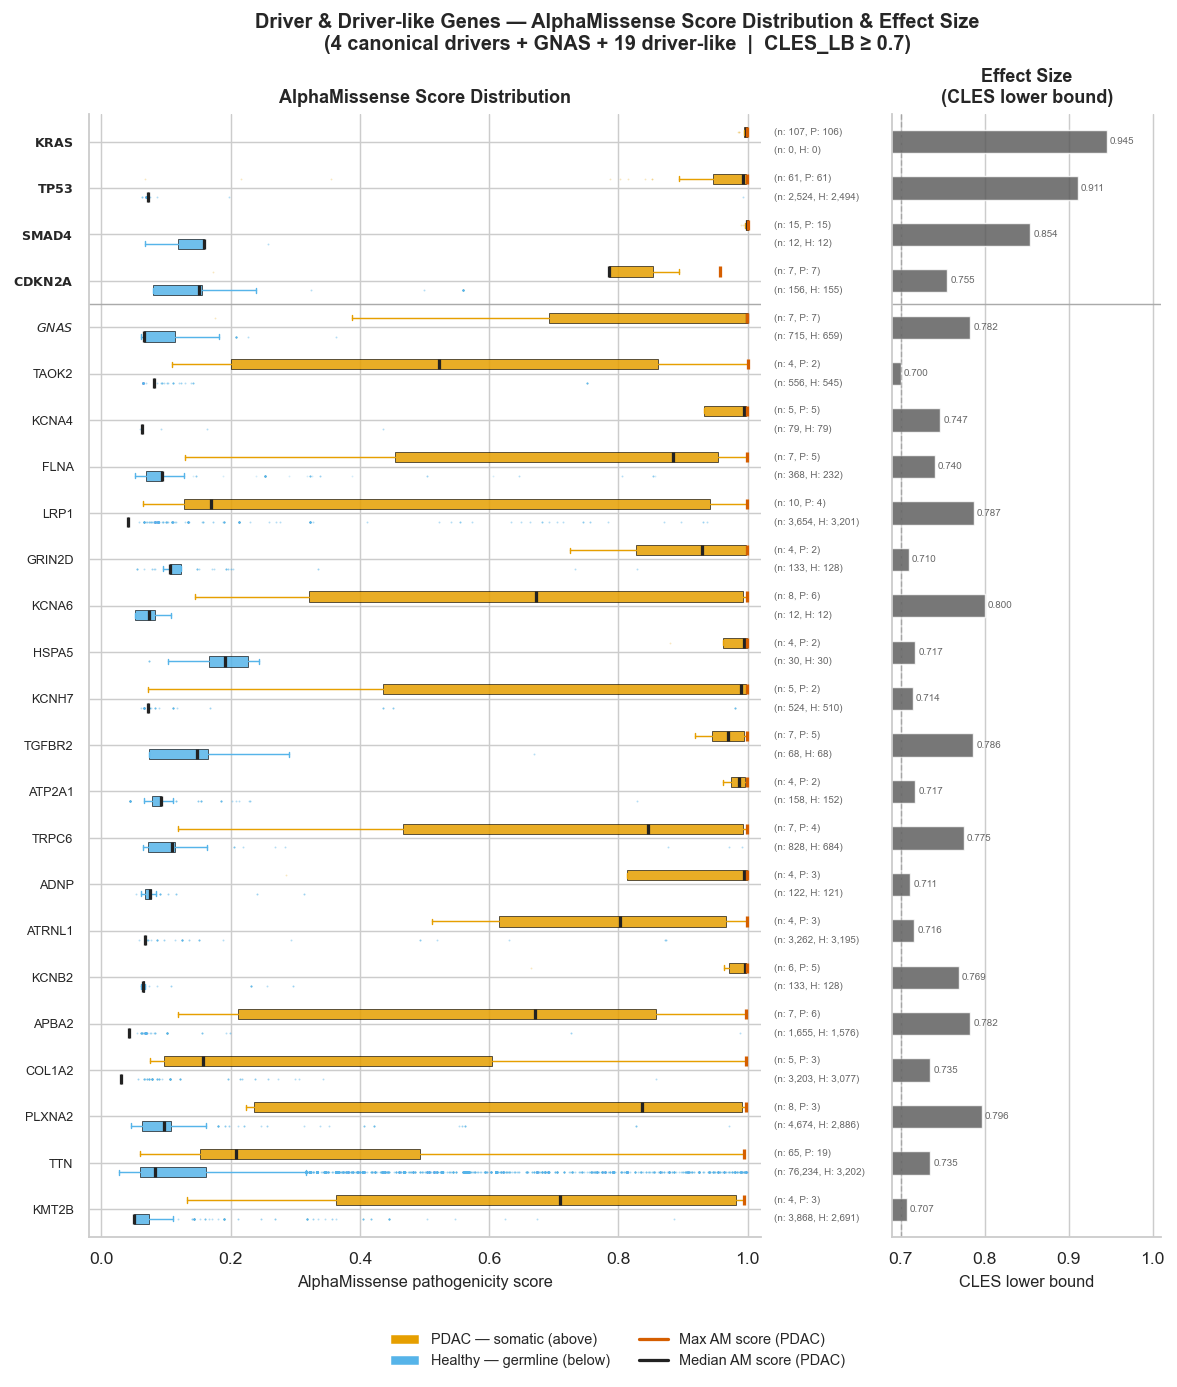

Saved to C:\2604_BRP\Bachelor_Research_Project\Figures


In [21]:
# ── Figure (KO2 p5-plot style) ────────────────────────────────────────────────
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

COLOR_CLES7 = '#555555'
OFFSET7, BOX_W7 = 0.20, 0.22
_y7   = list(range(_n7))
YLIM7 = (-0.6, _n7 - 0.4)

fig7 = plt.figure(figsize=(11, _n7 * 0.42 + 1.0))
gs7  = gridspec.GridSpec(
    1, 2, figure=fig7,
    width_ratios=[4.5, 1.8],
    wspace=0.28, left=0.13, right=0.88, top=0.90, bottom=0.12,
)
ax_box7  = fig7.add_subplot(gs7[0])
ax_cles7 = fig7.add_subplot(gs7[1])
kw7 = dict(vert=False, widths=BOX_W7, patch_artist=True, manage_ticks=False)

# ── Left panel: boxplots ──────────────────────────────────────────────────────
for y, g, p, h, np_, nh, pi_, hi_ in zip(
    _y7, _rows7, _pd7, _hd7,
    [len(x) for x in _pd7], [len(x) for x in _hd7],
    _pdac_ind7, _hlth_ind7
):
    if len(p) >= 2:
        ax_box7.boxplot(
            [p], positions=[y + OFFSET7], **kw7,
            medianprops  = dict(color='#222222', lw=1.8),
            boxprops     = dict(facecolor=COLOR_PDAC, alpha=0.85, lw=0.4),
            whiskerprops = dict(lw=0.8, color=COLOR_PDAC),
            capprops     = dict(lw=0.8, color=COLOR_PDAC),
            flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                markerfacecolor=COLOR_PDAC, markeredgecolor='none'),
        )
        ax_box7.vlines(p.max(),
                       y + OFFSET7 - BOX_W7/2, y + OFFSET7 + BOX_W7/2,
                       color='#D55E00', lw=1.8, zorder=4)
    ax_box7.text(1.02, y + OFFSET7, f'(n: {np_:,}, P: {pi_:,})',
                 va='center', transform=ax_box7.get_yaxis_transform(),
                 fontsize=5.5, color='#666')

    if len(h) >= 2:
        ax_box7.boxplot(
            [h], positions=[y - OFFSET7], **kw7,
            medianprops  = dict(color='#222222', lw=1.8),
            boxprops     = dict(facecolor=COLOR_HEALTHY, alpha=0.85, lw=0.4),
            whiskerprops = dict(lw=0.8, color=COLOR_HEALTHY),
            capprops     = dict(lw=0.8, color=COLOR_HEALTHY),
            flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                markerfacecolor=COLOR_HEALTHY, markeredgecolor='none'),
        )
    ax_box7.text(1.02, y - OFFSET7,
                 f'(n: {nh:,}, H: {hi_:,})' if hi_ > 0 else '(n: 0, H: 0)',
                 va='center', transform=ax_box7.get_yaxis_transform(),
                 fontsize=5.5, color='#666')

ax_box7.set_xlim(-0.02, 1.02)
ax_box7.set_ylim(*YLIM7)
ax_box7.set_yticks(_y7)

# Gene label formatting: bold canonical + GNAS, italic GNAS
_BOLD7 = _driver_set7 | {'GNAS'}
ax_box7.set_yticklabels(
    [
        (f'$\\mathbf{{\\mathit{{{g}}}}}$' if g == 'GNAS' else f'$\\mathbf{{{g}}}$')
        if g in _BOLD7 else g
        for g in _rows7
    ],
    fontsize=7,
)
ax_box7.axhline(SEP7, color='#aaa', lw=0.8)
ax_box7.set_xlabel('AlphaMissense pathogenicity score', fontsize=9)
ax_box7.set_title('AlphaMissense Score Distribution', fontsize=10, pad=6, fontweight='bold')
sns.despine(ax=ax_box7)

# ── Right panel: CLES bars ────────────────────────────────────────────────────
_cles_vals7 = [c if c is not None else 0 for c in _cles7]
_cles_min7  = max(0.69, min(c for c in _cles_vals7 if c > 0) - 0.01) if any(_cles_vals7) else 0.69
ax_cles7.barh(_y7, _cles_vals7, left=0, color=COLOR_CLES7, height=0.50, alpha=0.80)
ax_cles7.axvline(0.70, color='grey', lw=0.8, ls='--', alpha=0.5)
for y, c in zip(_y7, _cles_vals7):
    if c > 0:
        ax_cles7.text(c + 0.004, y, f'{c:.3f}', va='center', fontsize=5.5, color='#666')
ax_cles7.set_xlim(_cles_min7, 1.01)
ax_cles7.set_ylim(*YLIM7)
ax_cles7.set_yticks([])
ax_cles7.axhline(SEP7, color='#aaa', lw=0.8)
ax_cles7.set_xlabel('CLES lower bound', fontsize=9)
ax_cles7.set_title('Effect Size\n(CLES lower bound)', fontsize=10, pad=6, fontweight='bold')
sns.despine(ax=ax_cles7)

# ── Title + legend ────────────────────────────────────────────────────────────
fig7.suptitle(
    'Driver & Driver-like Genes — AlphaMissense Score Distribution & Effect Size\n'
    '(4 canonical drivers + GNAS + 19 driver-like  |  CLES_LB ≥ 0.7)',
    fontsize=11, fontweight='semibold', y=0.97,
)
from matplotlib.patches import Patch
_leg7 = [
    Patch(facecolor=COLOR_PDAC,    label='PDAC — somatic (above)'),
    Patch(facecolor=COLOR_HEALTHY, label='Healthy — germline (below)'),
    Line2D([], [], color='#D55E00', lw=1.8, label='Max AM score (PDAC)'),
    Line2D([], [], color='#222222', lw=1.8, label='Median AM score (PDAC)'),
]
fig7.legend(handles=_leg7, loc='lower center', bbox_to_anchor=(0.5, 0.02),
            bbox_transform=fig7.transFigure,
            frameon=False, fontsize=8, ncol=2)

_figname7 = 'KO5_driver_gene_distributions'
fig7.savefig(out_dir / f'{_figname7}.pdf', dpi=300, bbox_inches='tight')
fig7.savefig(out_dir / f'{_figname7}.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    fig7.savefig(out_dir / f'{_figname7}.svg', bbox_inches='tight')
plt.show()
print('Saved to', out_dir.resolve())

### 7b. Score Distribution — Grouped by Evidence Category

Same 24 genes as Section 7, reordered into the four categories used in the highly pathogenic mutations table (Section 5): canonical driver genes, and driver-like genes split into confirmed PDAC drivers, novel candidates, and insufficient-evidence candidates. GNAS moves from its earlier stand-alone row into the confirmed-drivers group. Ordering within each category follows the same AlphaMissense-max ranking used in Section 7.

In [ ]:
# ── Section 7b: Section 7 gene set, grouped by evidence category (Table 5) ──────
# Categories mirror the highly pathogenic mutations table (Section 5):
#   Canonical driver genes | Confirmed PDAC drivers | Novel candidates | Insufficient evidence
CONFIRMED_GENES    = ['GNAS', 'TGFBR2', 'HSPA5', 'LRP1', 'COL1A2', 'KMT2B']
NOVEL_GENES        = ['FLNA', 'TAOK2', 'TRPC6', 'ADNP', 'PLXNA2']
INSUFFICIENT_GENES = ['KCNA4', 'KCNA6', 'KCNB2', 'KCNH7', 'GRIN2D', 'APBA2', 'ATP2A1', 'TTN', 'ATRNL1']

_cat_blocks7b = [
    ('Canonical\ndriver genes', DRIVER_GENES),
    ('Confirmed\nPDAC drivers', _sort_labels(CONFIRMED_GENES,    'Driver-like')),
    ('Novel\ncandidates',       _sort_labels(NOVEL_GENES,        'Driver-like')),
    ('Insufficient\nevidence',  _sort_labels(INSUFFICIENT_GENES, 'Driver-like')),
]

_genes7b = [g for _, genes in _cat_blocks7b for g in genes]
assert set(_genes7b) == set(_genes7), f'gene set mismatch vs Section 7: {set(_genes7) ^ set(_genes7b)}'
_n7b    = len(_genes7b)
_rows7b = list(reversed(_genes7b))

# Separator positions and label spans (row index, bottom-up) per category block
_seps7b   = []
_labels7b = []
_cum = 0
for name, genes in _cat_blocks7b:
    size = len(genes)
    hi   = _n7b - 1 - _cum
    lo   = _n7b - _cum - size
    _labels7b.append((name, lo, hi))
    _cum += size
    if _cum < _n7b:
        _seps7b.append(_n7b - _cum - 0.5)

print('Section 7b categories:')
for name, genes in _cat_blocks7b:
    print(f'  {name.replace(chr(10), " "):22s}: {genes}')

# Re-use score arrays / CLES / counts computed in Section 7 (same gene universe)
_pd7b       = [_pdac_sc7.get(g, np.array([])) for g in _rows7b]
_hd7b       = [_healthy_sc7.get(g, np.array([])) for g in _rows7b]
_cles7b     = [_cles_map.get(g, None) for g in _rows7b]
_pdac_ind7b = [_n_pdac_7.get(g, 0) for g in _rows7b]
_hlth_ind7b = [_n_hlth_7.get(g, 0) for g in _rows7b]

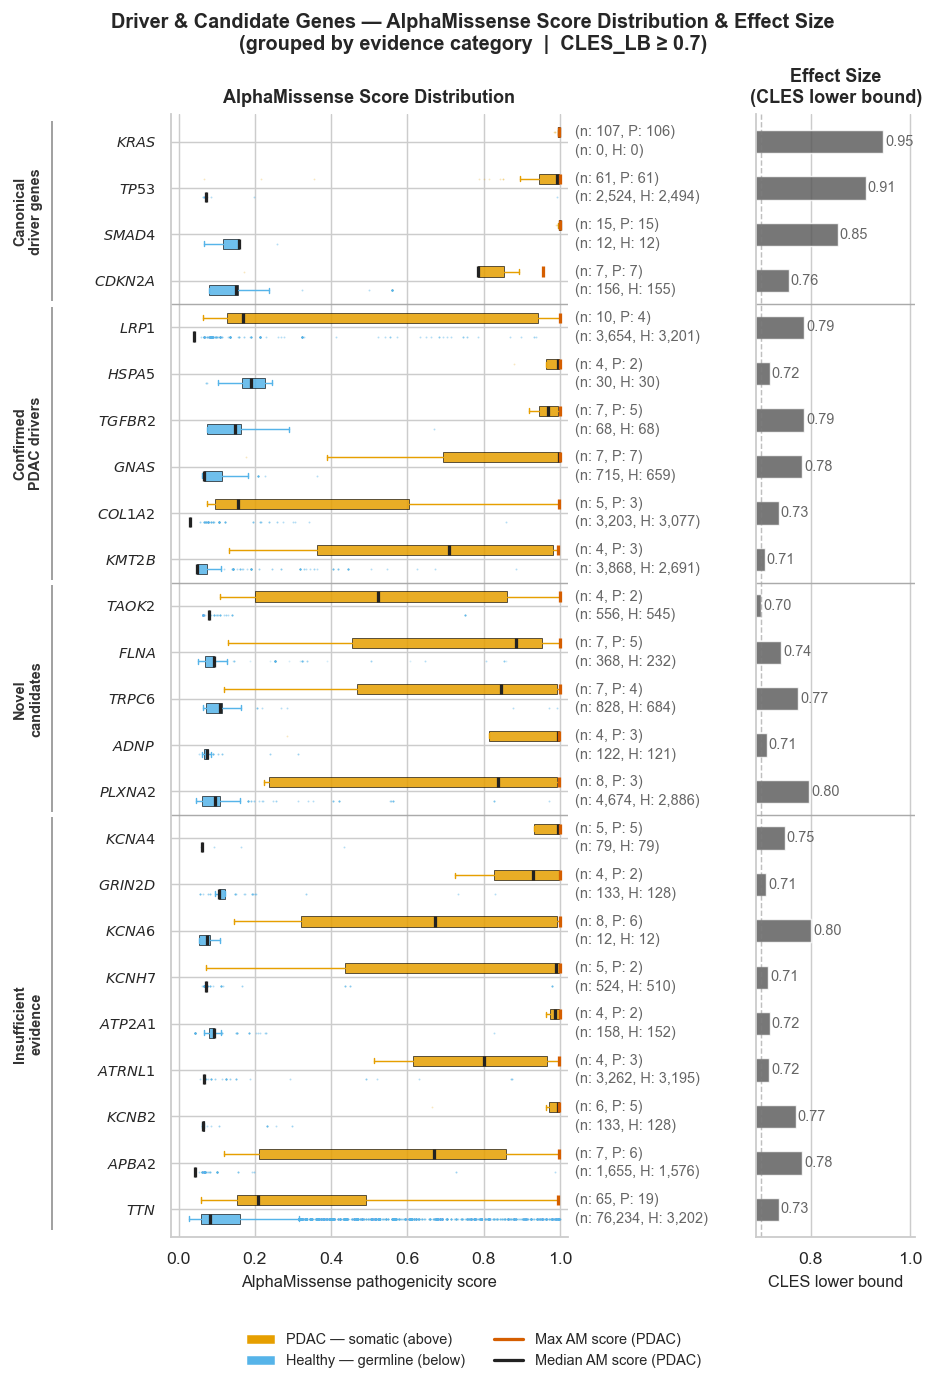

Saved to C:\2604_BRP\Bachelor_Research_Project\Figures


In [30]:
# ── Figure 7b (category-grouped variant of Section 7) ────────────────────────
# Helvetica (falls back to Arial locally; SVG keeps the font-family chain so it
# renders as Helvetica wherever that font is installed) and an 8pt font floor.
FONT7B = {
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
    'svg.fonttype': 'none',
}
# 183 mm required *rendered* figure width. savefig uses bbox_inches='tight',
# which crops trailing whitespace, so the nominal figsize must be inflated by
# a calibration factor (empirically ~1.213x for this layout) to land on 183 mm
# after cropping -- verified against the saved PNG at 300 dpi.
FIG_WIDTH_IN7B = 8.944

with mpl.rc_context(FONT7B):
    _y7b   = list(range(_n7b))
    YLIM7b = (-0.6, _n7b - 0.4)

    fig7b = plt.figure(figsize=(FIG_WIDTH_IN7B, _n7b * 0.42 + 1.0))
    gs7b  = gridspec.GridSpec(
        1, 2, figure=fig7b,
        width_ratios=[4.5, 1.8],
        wspace=0.68, left=0.24, right=0.88, top=0.90, bottom=0.12,
    )
    ax_box7b  = fig7b.add_subplot(gs7b[0])
    ax_cles7b = fig7b.add_subplot(gs7b[1])

    # ── Left panel: boxplots ──────────────────────────────────────────────────────
    for y, g, p, h, np_, nh, pi_, hi_ in zip(
        _y7b, _rows7b, _pd7b, _hd7b,
        [len(x) for x in _pd7b], [len(x) for x in _hd7b],
        _pdac_ind7b, _hlth_ind7b
    ):
        if len(p) >= 2:
            ax_box7b.boxplot(
                [p], positions=[y + OFFSET7], **kw7,
                medianprops  = dict(color='#222222', lw=1.8),
                boxprops     = dict(facecolor=COLOR_PDAC, alpha=0.85, lw=0.4),
                whiskerprops = dict(lw=0.8, color=COLOR_PDAC),
                capprops     = dict(lw=0.8, color=COLOR_PDAC),
                flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                    markerfacecolor=COLOR_PDAC, markeredgecolor='none'),
            )
            ax_box7b.vlines(p.max(),
                           y + OFFSET7 - BOX_W7/2, y + OFFSET7 + BOX_W7/2,
                           color='#D55E00', lw=1.8, zorder=4)
        ax_box7b.text(1.02, y + OFFSET7, f'(n: {np_:,}, P: {pi_:,})',
                     va='center', transform=ax_box7b.get_yaxis_transform(),
                     fontsize=8, color='#666')

        if len(h) >= 2:
            ax_box7b.boxplot(
                [h], positions=[y - OFFSET7], **kw7,
                medianprops  = dict(color='#222222', lw=1.8),
                boxprops     = dict(facecolor=COLOR_HEALTHY, alpha=0.85, lw=0.4),
                whiskerprops = dict(lw=0.8, color=COLOR_HEALTHY),
                capprops     = dict(lw=0.8, color=COLOR_HEALTHY),
                flierprops   = dict(marker='.', ms=2, alpha=0.25,
                                    markerfacecolor=COLOR_HEALTHY, markeredgecolor='none'),
            )
        ax_box7b.text(1.02, y - OFFSET7,
                     f'(n: {nh:,}, H: {hi_:,})' if hi_ > 0 else '(n: 0, H: 0)',
                     va='center', transform=ax_box7b.get_yaxis_transform(),
                     fontsize=8, color='#666')

    ax_box7b.set_xlim(-0.02, 1.02)
    ax_box7b.set_ylim(*YLIM7b)
    ax_box7b.set_yticks(_y7b)

    # Gene label formatting: italic (gene symbol convention), bold for canonical + GNAS
    ax_box7b.set_yticklabels(
        [
            f'$\\mathbf{{\\mathit{{{g}}}}}$' if g in _BOLD7 else f'$\\mathit{{{g}}}$'
            for g in _rows7b
        ],
        fontsize=8,
    )
    for _sep in _seps7b:
        ax_box7b.axhline(_sep, color='#aaa', lw=0.8)

    # ── Left-margin category brackets + rotated labels ────────────────────────────
    _X_BRACKET7B, _X_LABEL7B = -0.30, -0.36
    for _name, _lo, _hi in _labels7b:
        ax_box7b.plot(
            [_X_BRACKET7B, _X_BRACKET7B], [_lo - 0.5 + 0.06, _hi + 0.5 - 0.06],
            transform=ax_box7b.get_yaxis_transform(),
            color='#999', lw=1.0, clip_on=False, solid_capstyle='butt',
        )
        ax_box7b.text(
            _X_LABEL7B, (_lo + _hi) / 2, _name,
            transform=ax_box7b.get_yaxis_transform(),
            rotation=90, ha='center', va='center', fontsize=8, color='#333',
            fontweight='bold', clip_on=False,
        )

    ax_box7b.set_xlabel('AlphaMissense pathogenicity score', fontsize=9)
    ax_box7b.set_title('AlphaMissense Score Distribution', fontsize=10, pad=6, fontweight='bold')
    sns.despine(ax=ax_box7b)

    # ── Right panel: CLES bars ────────────────────────────────────────────────────
    _cles_vals7b = [c if c is not None else 0 for c in _cles7b]
    _cles_min7b  = max(0.69, min(c for c in _cles_vals7b if c > 0) - 0.01) if any(_cles_vals7b) else 0.69
    ax_cles7b.barh(_y7b, _cles_vals7b, left=0, color=COLOR_CLES7, height=0.50, alpha=0.80)
    ax_cles7b.axvline(0.70, color='grey', lw=0.8, ls='--', alpha=0.5)
    for y, c in zip(_y7b, _cles_vals7b):
        if c > 0:
            ax_cles7b.text(c + 0.004, y, f'{c:.2f}', va='center', fontsize=8, color='#666')
    ax_cles7b.set_xlim(_cles_min7b, 1.01)
    ax_cles7b.set_ylim(*YLIM7b)
    ax_cles7b.set_yticks([])
    for _sep in _seps7b:
        ax_cles7b.axhline(_sep, color='#aaa', lw=0.8)
    ax_cles7b.set_xlabel('CLES lower bound', fontsize=9)
    ax_cles7b.set_title('Effect Size\n(CLES lower bound)', fontsize=10, pad=6, fontweight='bold')
    sns.despine(ax=ax_cles7b)

    # ── Title + legend ────────────────────────────────────────────────────────────
    fig7b.suptitle(
        'Driver & Candidate Genes — AlphaMissense Score Distribution & Effect Size\n'
        '(grouped by evidence category  |  CLES_LB ≥ 0.7)',
        fontsize=11, fontweight='semibold', y=0.97,
    )
    fig7b.legend(handles=_leg7, loc='lower center', bbox_to_anchor=(0.5, 0.02),
                bbox_transform=fig7b.transFigure,
                frameon=False, fontsize=8, ncol=2)

    _figname7b = 'KO5_driver_gene_distributions_by_category'
    fig7b.savefig(out_dir / f'{_figname7b}.pdf', dpi=300, bbox_inches='tight')
    fig7b.savefig(out_dir / f'{_figname7b}.png', dpi=300, bbox_inches='tight')
    fig7b.savefig(out_dir / f'{_figname7b}.svg', bbox_inches='tight')
    plt.show()
    print('Saved to', out_dir.resolve())

## 8. Cross-Method Comparison

Comparison of apparent performance (estimated on the training data) versus cross-validated performance, to assess the degree of optimism in apparent metrics. Box plots show the distribution of each metric over 500 folds.

In [29]:
# ── Section 8: Apparent vs. CV comparison with full 95% CI ─────────────────────
# Apparent CI: 100 subagging values (subagging spread only — no fold breakdown).
# CV CI      : 500 per-fold values (total spread: subagging + fold variation).
# Footnote % : computed at runtime from fold_auprc variance decomposition.
# Requires the bootstrap CV cell above to have been run (for sub_records_h).
from great_tables import GT, md, style, loc

# ── Helper: median (2.5th–97.5th percentile) ────────────────────────────────
def _ci_fmt(vals, d=3):
    m, lo, hi = (float(np.median(vals)),
                 float(np.percentile(vals,  2.5)),
                 float(np.percentile(vals, 97.5)))
    return f'{m:.{d}f} ({lo:.{d}f}\u2013{hi:.{d}f})'

# ── Apparent: 100 subagging values ───────────────────────────────────────────
_keys_cmp = ['f1', 'precision', 'recall', 'specificity', 'auprc', 'auc_roc']
_app_v = {k: [r[k] for r in sub_records_e] for k in _keys_cmp}

# ── CV: 500 per-fold values (100 bootstraps × 5 folds) ──────────────────────
_cv_fold = {
    'f1':          [v for r in sub_records_g for v in r['fold_f1']],
    'precision':   [v for r in sub_records_g for v in r['fold_prec']],
    'recall':      [v for r in sub_records_g for v in r['fold_rec']],
    'specificity': [v for r in sub_records_g for v in r['fold_spec']],
    'auprc':       [v for r in sub_records_g for v in r['fold_auprc']],
    'auc_roc':     [v for r in sub_records_g for v in r['fold_auc_roc']],
}

# ── Classical vs Basal-like AUROC: 500 per-fold values, flipped if needed ───
_roc_h_raw = [v for r in sub_records_h for v in r['fold_auc_roc']]
_roc_h = [1 - v for v in _roc_h_raw] if np.median(_roc_h_raw) < 0.5 else _roc_h_raw

# ── Variance decomposition for footnote (CV AUPRC) ─────────────────────────────
_auprc_boot_means = [float(np.mean(r['fold_auprc'])) for r in sub_records_g]
_auprc_boot_vars  = [float(np.var(r['fold_auprc']))  for r in sub_records_g]
_var_subag_auprc  = float(np.var(_auprc_boot_means))
_var_fold_auprc   = float(np.mean(_auprc_boot_vars))
_pct_fold_auprc   = round(_var_fold_auprc / (_var_subag_auprc + _var_fold_auprc) * 100)
_pct_subag_auprc  = 100 - _pct_fold_auprc

# ── Build rows ───────────────────────────────────────────────────────────────
_rows_cmp_g = [
    {'Metric': 'F1',
     'Apparent': _ci_fmt(_app_v['f1']),
     'CV':       _ci_fmt(_cv_fold['f1'])},
    {'Metric': 'Precision',
     'Apparent': _ci_fmt(_app_v['precision']),
     'CV':       _ci_fmt(_cv_fold['precision'])},
    {'Metric': 'Recall',
     'Apparent': _ci_fmt(_app_v['recall']),
     'CV':       _ci_fmt(_cv_fold['recall'])},
    {'Metric': 'Specificity',
     'Apparent': _ci_fmt(_app_v['specificity']),
     'CV':       _ci_fmt(_cv_fold['specificity'])},
    {'Metric': 'AUPRC \u2020',
     'Apparent': _ci_fmt(_app_v['auprc']),
     'CV':       _ci_fmt(_cv_fold['auprc'])},
    {'Metric': 'AUROC \u2020  (PDAC vs Healthy)',
     'Apparent': _ci_fmt(_app_v['auc_roc']),
     'CV':       _ci_fmt(_cv_fold['auc_roc'])},
    {'Metric': 'AUROC \u2021  (Classical vs Basal-like)',
     'Apparent': '\u2014',
     'CV':       _ci_fmt(_roc_h)},
]
_df_cmp_g = pl.DataFrame(_rows_cmp_g)

(
    GT(_df_cmp_g)
    .tab_header(
        title=md('**Set C — Apparent vs. Cross-Validated Performance**'),
        subtitle=md(
            '**Apparent:** threshold derived and evaluated on the *same* full cohort.  '
            '**CV:** 5-fold OOF results.  '
            'Values: median (2.5th\u201397.5th percentile).'
        ),
    )
    .tab_source_note(
        md(f'Apparent 95\u202f% CI: N\u202f=\u202f100 subagging iterations (spread from healthy-cohort resampling only).  '
           f'CV 95\u202f% CI: N\u202f=\u202f500 per-fold values (100\u202f\u00d7\u202f5 folds; total spread).  '
           f'Variance decomposition (AUPRC \u00a7G): ~{_pct_fold_auprc}\u202f% from fold assignment, ~{_pct_subag_auprc}\u202f% from subagging.  '
           f'\u2020\u202fThreshold-independent rank metrics \u2014 Apparent\u202f\u2248\u202fCV by construction.  '
           f'\u2021\u202fClassical vs Basal-like (\u00a7F, Set C, max AM, 100 patient bootstraps\u202f\u00d7\u202f5 folds); no Apparent baseline for this task.')
    )
    .tab_style(
        style=style.text(weight='bold'),
        locations=loc.body(rows=[0, 4, 5, 6]),
    )
    .tab_style(
        style=style.text(color='#999999'),
        locations=loc.body(columns=['Apparent'], rows=[6]),
    )
    .cols_align('center', columns=['Apparent', 'CV'])
    .cols_label(**{'Apparent': 'Apparent (\u00a7C)', 'CV': 'Cross-validated (\u00a7G / \u00a7F)'})
)

GT(_tbl_data=shape: (7, 3)
┌─────────────────────────────────┬─────────────────────┬─────────────────────┐
│ Metric                          ┆ Apparent            ┆ CV                  │
│ ---                             ┆ ---                 ┆ ---                 │
│ str                             ┆ str                 ┆ str                 │
╞═════════════════════════════════╪═════════════════════╪═════════════════════╡
│ F1                              ┆ 0.891 (0.870–0.903) ┆ 0.899 (0.800–0.954) │
│ Precision                       ┆ 0.929 (0.888–0.960) ┆ 0.929 (0.814–1.000) │
│ Recall                          ┆ 0.856 (0.844–0.856) ┆ 0.909 (0.742–0.912) │
│ Specificity                     ┆ 0.997 (0.994–0.998) ┆ 0.997 (0.991–1.000) │
│ AUPRC †                         ┆ 0.899 (0.866–0.919) ┆ 0.896 (0.781–0.990) │
│ AUROC †  (PDAC vs Healthy)      ┆ 0.968 (0.966–0.969) ┆ 0.959 (0.937–0.999) │
│ AUROC ‡  (Classical vs Basal-l… ┆ —                   ┆ 0.552 (0.331–0.776) │
└─────────────────────────────────┴─────────────────────┴─────────────────────┘, _body=<great_tables._gt_data.Body object at 0x000001DA03CAEC50>, _boxhead=Boxhead([ColInfo(var='Metric', type=<ColInfoTypeEnum.default: 1>, column_label='Metric', column_align='left', column_width=None), ColInfo(var='Apparent', type=<ColInfoTypeEnum.default: 1>, column_label='Apparent (§C)', column_align='center', column_width=None), ColInfo(var='CV', type=<ColInfoTypeEnum.default: 1>, column_label='Cross-validated (§G / §F)', column_align='center', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x000001DA03C89350>, _spanners=Spanners([]), _heading=Heading(title=Md(text='**Set C — Apparent vs. Cross-Validated Performance**'), subtitle=Md(text='**Apparent:** threshold derived and evaluated on the *same* full cohort.  **CV:** 5-fold OOF results.  Values: median (2.5th–97.5th percentile).'), preheader=None), _stubhead=None, _summary_rows=<great_tables._gt_data.SummaryRows object at 0x000001DA03BF2250>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x000001DA03DBDD00>, _source_notes=[Md(text='Apparent 95\u202f% CI: N\u202f=\u202f100 subagging iterations (spread from healthy-cohort resampling only).  CV 95\u202f% CI: N\u202f=\u202f500 per-fold values (100\u202f×\u202f5 folds; total spread).  Variance decomposition (AUPRC §G): ~94\u202f% from fold assignment, ~6\u202f% from subagging.  †\u202fThreshold-independent rank metrics — Apparent\u202f≈\u202fCV by construction.  ‡\u202fClassical vs Basal-like (§F, Set C, max AM, 100 patient bootstraps\u202f×\u202f5 folds); no Apparent baseline for this task.')], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=[0, 4, 5, 6], mask=None), grpname=None, colname='Metric', rownum=0, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 4, 5, 6], mask=None), grpname=None, colname='Metric', rownum=4, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 4, 5, 6], mask=None), grpname=None, colname='Metric', rownum=5, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 4, 5, 6], mask=None), grpname=None, colname='Metric', rownum=6, colnum=None, styles=[CellStyleText(color=None, font=None, size=None, align=None, v_align=None, style=None, weight='bold', stretch=None, decorate=None, transform=None, whitespace=None)]), StyleInfo(locname=LocBody(columns=None, rows=[0, 4, 5, 6], mask=None), grpname=None, colname='Apparent', rownum=0, colnum=None, styles=[CellStyleTe

Note: Classical vs Basal-like AUROC flipped (positive class swapped to obtain AUROC > 0.5)
AUPRC     : n=500  median=0.896  SD=0.055
AUROC   : n=500   median=0.552  SD=0.116
Saved to C:\Users\daane\Desktop\GitHub Repos\Bachelor_Research_Project\Figures


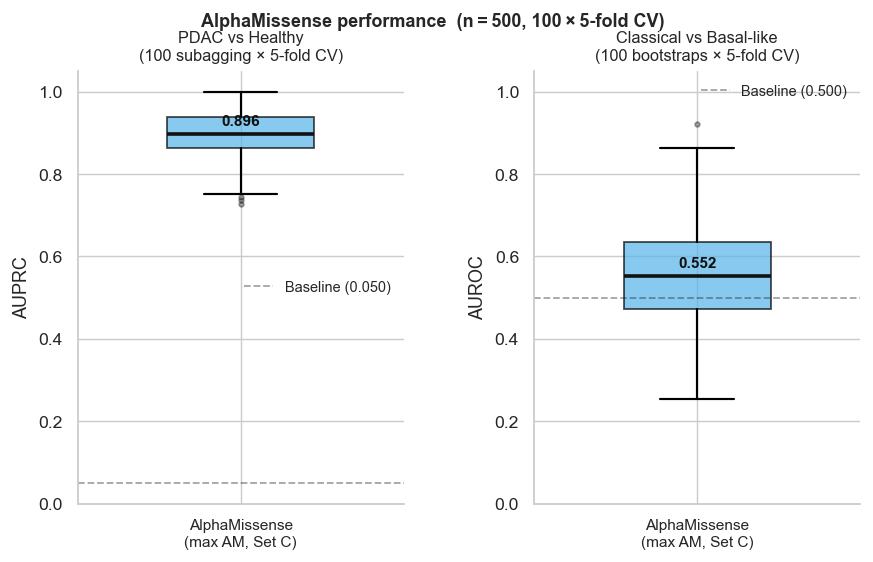

Saved: M1_H_boxplots.png


In [30]:
# ── Section 8: metric distribution box plots ─────────────────────────────────────
_auprc_500   = [v for r in sub_records_g for v in r['fold_auprc']]
_roc_500_raw = [v for r in sub_records_h for v in r['fold_auc_roc']]

# Flip Classical vs Basal-like AUROC if classifier scores Basal-like higher than Classical
if np.median(_roc_500_raw) < 0.5:
    _roc_500 = [1 - v for v in _roc_500_raw]
    print('Note: Classical vs Basal-like AUROC flipped (positive class swapped to obtain AUROC > 0.5)')
else:
    _roc_500 = _roc_500_raw

print(f'AUPRC     : n={len(_auprc_500)}  median={np.median(_auprc_500):.3f}  SD={np.std(_auprc_500):.3f}')
print(f'AUROC   : n={len(_roc_500)}   median={np.median(_roc_500):.3f}  SD={np.std(_roc_500):.3f}')

_fig_h, (_ax_g_h, _ax_f_h) = plt.subplots(1, 2, figsize=(7, 4.5))
_fig_h.subplots_adjust(wspace=0.40, left=0.11, right=0.97,
                       top=0.88, bottom=0.14)

_METHOD_LABEL = 'AlphaMissense\n(max AM, Set C)'
_prev_g_h = float(y_full[~np.isin(all_ids, list(_outlier_t1))].mean())

for _ax_h, _vals_h, _metric_h, _baseline_h in [
    (_ax_g_h, _auprc_500, 'AUPRC',   _prev_g_h),
    (_ax_f_h, _roc_500,   'AUROC', 0.5),
]:
    _ax_h.boxplot(
        _vals_h, positions=[0], widths=0.45,
        patch_artist=True,
        boxprops=dict(facecolor=WONG['sky_blue'], alpha=0.7),
        medianprops=dict(color='#111111', lw=2),
        whiskerprops=dict(lw=1.2),
        capprops=dict(lw=1.2),
        flierprops=dict(marker='o', markersize=2.5,
                        markerfacecolor='#555555', alpha=0.4,
                        linestyle='none'),
    )
    # Annotate median value just above the median line
    _med_h = float(np.median(_vals_h))
    _ax_h.text(0, _med_h + 0.015, f'{_med_h:.3f}',
               ha='center', va='bottom', fontsize=8.5,
               fontweight='bold', color='#111111')
    _ax_h.axhline(_baseline_h, color='k', lw=1, ls='--', alpha=0.4,
                  label=f'Baseline ({_baseline_h:.3f})')
    _ax_h.set_xticks([0])
    _ax_h.set_xticklabels([_METHOD_LABEL], fontsize=8.5)
    _ax_h.set_ylabel(_metric_h, fontsize=10)
    _ax_h.set_ylim(0, 1.05)
    _ax_h.legend(fontsize=8, frameon=False)
    sns.despine(ax=_ax_h)

_ax_g_h.set_title('PDAC vs Healthy\n(100 subagging × 5-fold CV)', fontsize=9)
_ax_f_h.set_title('Classical vs Basal-like\n(100 bootstraps × 5-fold CV)',
                   fontsize=9)
_fig_h.suptitle(
    'AlphaMissense performance  (n = 500, 100 × 5-fold CV)',
    fontsize=10, fontweight='bold',
)
_figname8 = 'KO5_H_boxplots'
plt.savefig(out_dir / f'{_figname8}.pdf', dpi=300, bbox_inches='tight')
plt.savefig(out_dir / f'{_figname8}.png', dpi=300, bbox_inches='tight')
with mpl.rc_context({'svg.fonttype': 'none'}):
    plt.savefig(out_dir / f'{_figname8}.svg', bbox_inches='tight')
print('Saved to', out_dir.resolve())
plt.show()
print('Saved: M1_H_boxplots.png')
